# Evoluzione degli anime negli anni

Gli anime non sono solo titoli da guardare: sono un ecosistema fatto di produzione, generi, personaggi, voci, fan e comunità globali.

In questo notebook racconteremo come questo ecosistema prende forma nei dati: dalla crescita storica degli anime fino al modo in cui gli utenti li valutano, li amano e li organizzano nelle proprie liste.

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
import ast
import plotly.express as px
from solution.utils import utils


In [2]:
# load dataset
df_details = pd.read_csv("../../dataset/cleaned/details_cleaned.csv")
df_favs = pd.read_csv("../../dataset/cleaned/favs_cleaned.csv")
df_recommendations = pd.read_csv("../../dataset/cleaned/recommendations_cleaned.csv")
df_stats = pd.read_csv("../../dataset/cleaned/stats_cleaned.csv")
df_ratings = pd.read_csv("../../dataset/cleaned/ratings_cleaned.csv")
df_profiles = pd.read_csv("../../dataset/cleaned/profiles_cleaned.csv")
df_person_anime_works = pd.read_csv("../../dataset/cleaned/person_anime_works_cleaned.csv")
df_person_details = pd.read_csv("../../dataset/cleaned/person_details_cleaned.csv")
df_person_alternate_names = pd.read_csv("../../dataset/cleaned/person_alternate_names_cleaned.csv")
df_characters_anime_works = pd.read_csv("../../dataset/cleaned/character_anime_works_cleaned.csv")
df_person_voice_works = pd.read_csv("../../dataset/cleaned/person_voice_works_cleaned.csv")
df_characters = pd.read_csv("../../dataset/cleaned/characters_cleaned.csv")
df_character_nicknames = pd.read_csv("../../dataset/cleaned/character_nicknames_cleaned.csv")

In [3]:
df_details['start_date'] = pd.to_datetime(df_details['start_date'], errors='coerce')
df_details['year'] = df_details['start_date'].dt.year.astype("Int64")
df_details['scored_by'] = pd.to_numeric(df_details['scored_by'], errors='coerce')
df_person_details["birthday"] = pd.to_datetime(df_person_details["birthday"], errors="coerce")
df_person_details["birth_year"] = df_person_details["birthday"].dt.year.astype("Int64")
df_person_details["favorites"] = pd.to_numeric(df_person_details["favorites"], errors="coerce")

## 1. LA CRESCITA STORICA DELLA PRODUZIONE ANIME

### Come si è evoluta la produzione di anime nel tempo?

In [4]:
details = df_details.copy()
# rimuove le righe senza data di inizio
details = details.dropna(subset=['start_date'])
# conta quanti anime ci sono per ogni anno
counts = (details['year'].value_counts().sort_index().reset_index())
# rinomina le colonne
counts.columns = ['year', 'anime_count']
# creazione grafico con Plotly
fig = px.line(counts,x='year',y='anime_count',markers=True,
    title="Numero di anime per anno di inizio",
    labels={'year': 'Anno di inizio','anime_count': 'Numero di anime'},
    hover_data={'year': True,'anime_count': True})
fig.update_traces(marker=dict(size=5),line=dict(width=2))
fig.update_layout(
    xaxis=dict(range=[1917, 2024]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

**La parabola della produzione: dal silenzio all'esplosione**

Per gran parte del Novecento, l'industria degli anime ha proceduto con un passo lento e constante. è stato un cammino silenzioso, fatto di sperimentazione e artigianalità, dove la produzione cresceva senza scosse evidenti. Ma è con l'arrivo degli anni '80 che qualcosa inizia a cambiare: il battito accelera, segnalando un interesse che travalica i confini nazionali.

**Il Nuovo Millennio e il picco storico**

Tuttavia, è dopo il 2000 che assistiamo a una vera e propria metamorfosi. La curva della produzione cambia ritmo in modo prepotente, spinta dalla digitalizzazione e da una domanda globale sempre più vorace. Questo crescendo culmina nel **2017**: l'anno d'oro, il vertice masssimo di un'espansione durata due decenni, in cui l'industria ha toccato il suo apice storico.

**Oltre la vetta: un nuovo equilibro**

Negli anni più recenti, i dati mostrano una lieva flessione. Non è però un segnale di crisi, ma il riflesso di un mercato che, dopo aver toccato vette incredibile nel 2017, cerca ora un nuovo equilibro. La tendenza generale rimane solida: il gigante è sveglio e continua a correre, consolidando la sua eredigtà come ecosistema culturale globale.
> **Nota sui dati:** su un totale di 28.955 titoli, 851 anime privi di data di inizio (2,9 % del dataset) sono stati esclusi da questo grafico. Il dataset contiene 157 titoli con anno 2026–2027 (annunciati ma non ancora usciti). Il grafico è volutamente limitato al 2024 per mostrare solo produzioni concluse.

### L'albero genealogico degli anime: distribuzione dei generi

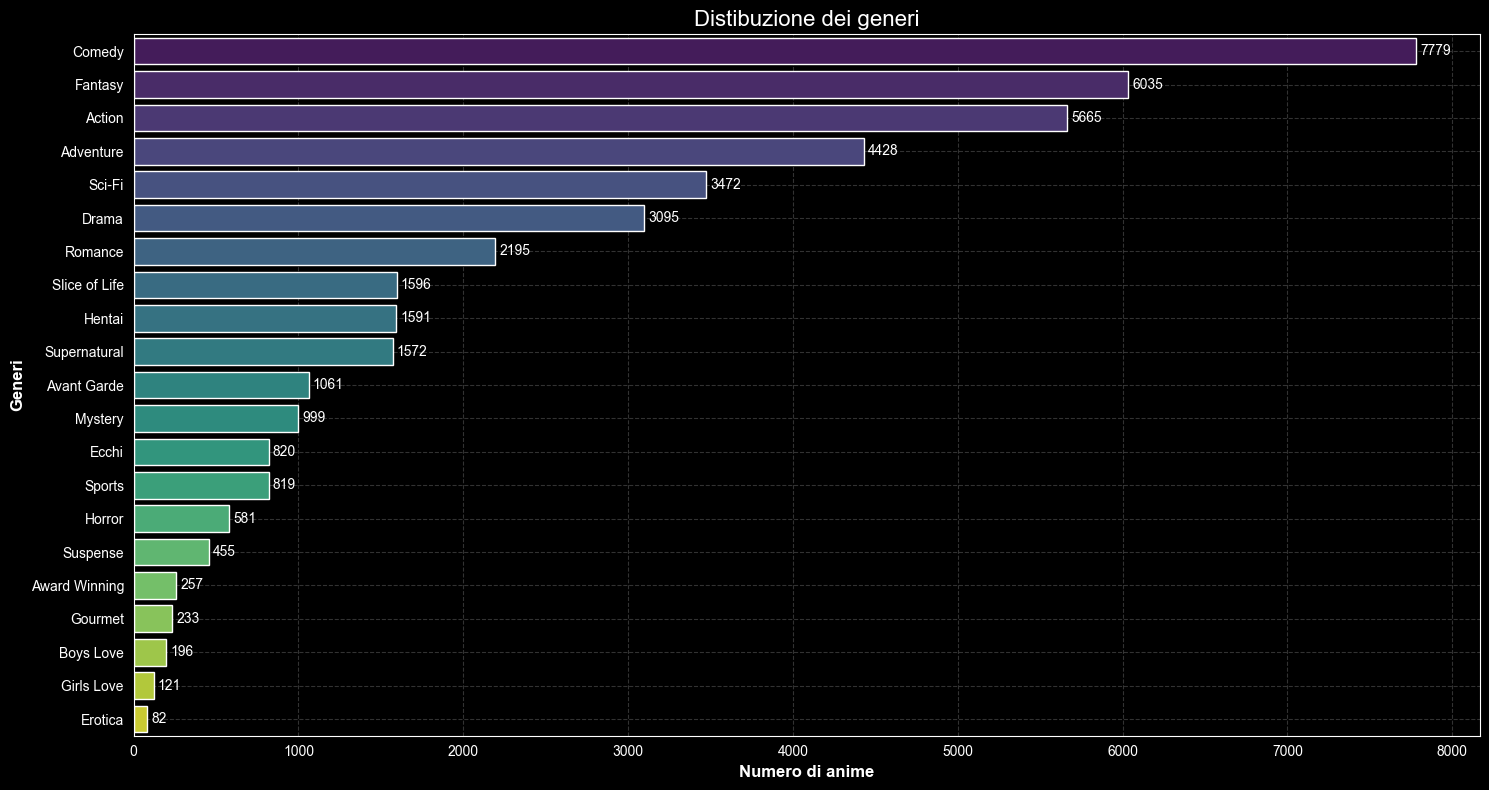

In [5]:
df_genres = df_details['genres'].copy()
# converte ogni valore da stringa in una lista
df_genres = df_genres.apply(utils.parse_genres)
# esplode le liste: ogni genere diventa una riga separata
df_genres = df_genres.explode().dropna()
# conta quante volte appare ogni genere
genre_count = df_genres.value_counts().reset_index()
# rinomia colonne
genre_count.columns = ['genre', 'count']
# crea grafico
plt.figure(figsize=(15, 8))
ax = sns.barplot(data=genre_count, x='count', y='genre', hue='genre', palette='viridis')
# per ogni barra mostra il numero esatto di anime
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Distibuzione dei generi', fontsize=16)
plt.xlabel('Numero di anime', fontsize=12, fontweight='bold')
plt.ylabel('Generi', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()


**I giganti del settore: i pilastri del mercato**
Se osserviamo la foresta dei contenuti prodotti, i giganti che dominano la scena sono indubbiamente la **Commedia**, l'**Azione** e il **Fantasy**. Questi generi costituiscono le fondamenta dell'intera industria: la loro popolarità universale li rende i prodotti più "sicuri" e richiesti, capaci di attrarre un pubblico vastissimo che spazia dai giovanissimi ai fan storici.

**L'equilibrio tra evasione e introspezione**

Accanto ai leader indiscussi, notiamo una presenza solida di generi come **Adventure** e **Sci-Fi**, che alimentano l'immaginario fantastico tipico del medium. Tuttavia, l'analisi rivela che non c'è solo spettacolo: il successo di titoli **Drama** e **Slice of Life** dimostra un'industria profondamente radicata nell'esplorazione dei sentimenti umani e della vita quotidiana, capace di trasformare la normalità in narrazione epica.
> **Nota sui dati:** Il 20,7 % degli anime (5.983 titoli) non ha tag di genere nel dataset e non è incluso in questo grafico né in quello successivo. La distribuzione si basa sul restante 79,3 % del catalogo.

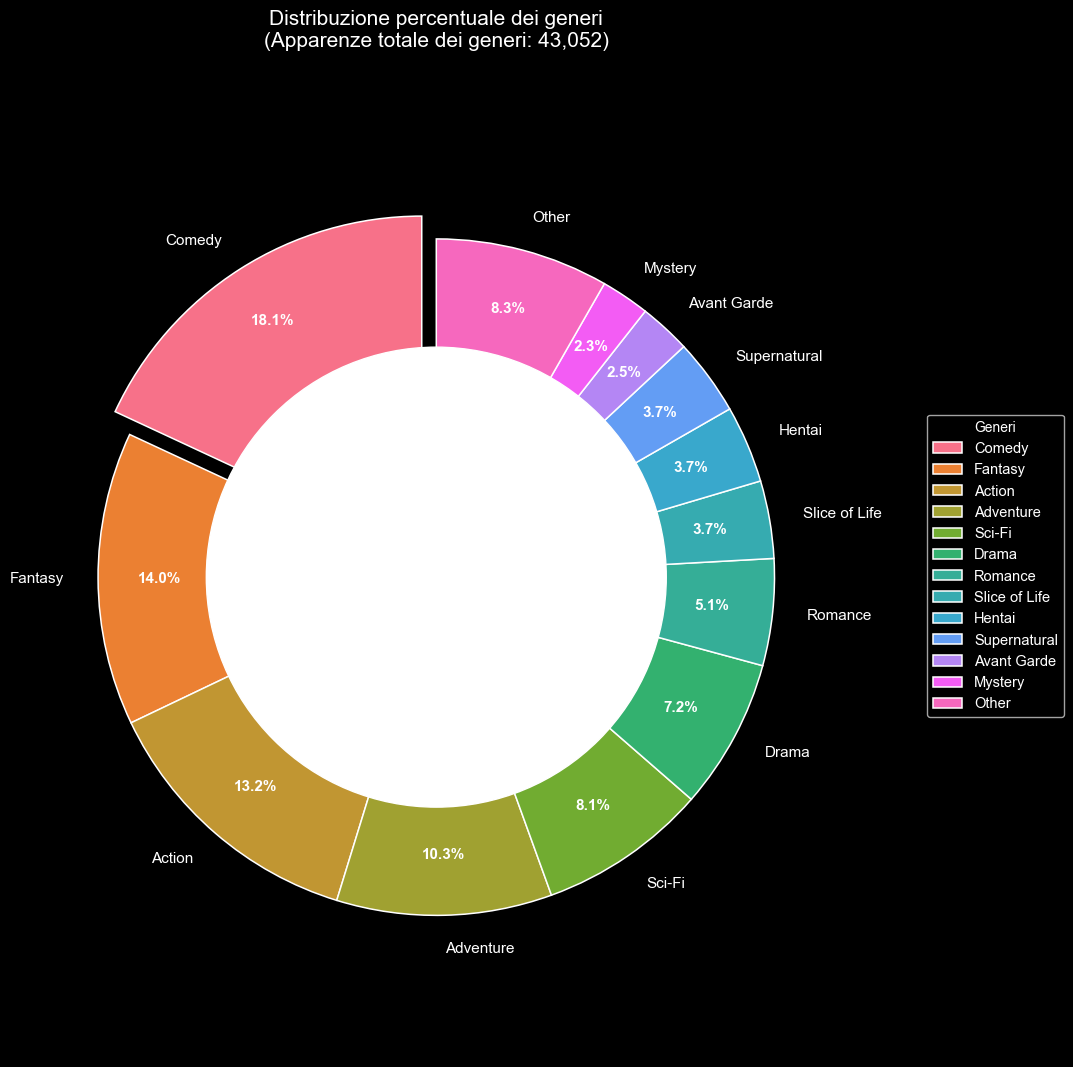

In [6]:
details = df_details.copy()
# rimuove le righe senza generi
details = details.dropna(subset=['genres'])
# usa la funzione utils per convertire la colonna generi in liste
details['genres'] = details['genres'].apply(utils.parse_genres)
# explode: una riga per ogni genere
genres_df = details.explode('genres')
# conta quante volte compare ogni genere
genre_total = genres_df['genres'].value_counts()
# top 12 generi + Other
top_n_pie = 12
top_genres_pie = genre_total.head(top_n_pie)
# somma il conteggio di tutti i generi rimanenti
other_count = genre_total.iloc[top_n_pie:].sum()
if other_count > 0:
    pie_data = pd.concat([
        top_genres_pie,
        pd.Series({'Other': other_count})
    ])
else:
    pie_data = top_genres_pie
plt.figure(figsize=(11, 11))
colors = sns.color_palette("husl", len(pie_data))
# explode solo sulla fetta più grande
explode = [0.08 if genre == pie_data.idxmax() else 0 for genre in pie_data.index]
wedges, texts, autotexts = plt.pie(pie_data.values,labels=pie_data.index,autopct='%1.1f%%',startangle=90,colors=colors,explode=explode,pctdistance=0.82,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.1},textprops={'fontsize': 11})
# stile percentuali
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
plt.title(f"Distribuzione percentuale dei generi\n(Apparenze totale dei generi: {genre_total.sum():,})",fontsize=15, pad=20)
# effetto donut
centre_circle = plt.Circle((0, 0), 0.68, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
# legenda
plt.legend(pie_data.index, title="Generi", loc="center left",bbox_to_anchor=(1.15, 0.5), fontsize=10.5)
plt.axis('equal')
plt.tight_layout()
plt.show()

**L'anima del mosaico: la forza delle nicchie**

Il grafico a ciambella ci offre una prospettiva diversa e fondamentale: quella della "biodiversità" del settore. Sebbene i generi dominanti occupino le fette più grandi, la vasta area definita dalle categorie minori rivela la vera magia degli anime. Non è un mercato a senso unico, ma un mosaico composto da centinaia di sfumature diverse che convivono armoniosamente.

**Visione d'insieme: un ecosistema multiforme**

In sintesi, l'equilibrio tra i generi **mainstream** (che garantiscono la stabilità economica) e le innumerevoli **nicchie** (che preservano la vivacità artistica) è il vero segreto del successo globale. Questa distribuzione ci restituisce l'immagine di un ecosistema maturo, dove ogni spettatore, indipendentemente da quanto siano particolari i suoi gusti, potrà sempre trovare una storia originale cucita su misura per lui.

### Come sono cambiati i generi anime nel tempo?

In [7]:
df_gen_evol = df_details.copy()
# rimuove righe senza anno
df_gen_evol = df_gen_evol.dropna(subset=['year'])
# filtra solo gli anime storicamente rilevanti
df_gen_evol = df_gen_evol[(df_gen_evol['year'] >= 1917) & (df_gen_evol['year'] <= 2024)]
# rimuove righe senza generi
df_gen_evol = df_gen_evol.dropna(subset=['genres'])
# converte la stringa dei generi in lista
df_gen_evol['genres'] = df_gen_evol['genres'].apply(utils.parse_genres)
# pulisce ogni genre: rimuove spazi e mette la prima lettera maiuscola
df_gen_evol['genres'] = df_gen_evol['genres'].apply(lambda g: [gen.strip().title() for gen in g])
# explode generi
genres_df = df_gen_evol.explode('genres')
# conteggio per anno e genere
genre_year = (genres_df.groupby(['year', 'genres']).size() .reset_index(name='count'))
# grafico
fig = go.Figure()
for genre in sorted(genre_year['genres'].unique()):
    df_g = genre_year[genre_year['genres'] == genre]
    fig.add_trace(
        go.Scatter(
            x=df_g['year'],
            y=df_g['count'],
            mode='lines',
            name=genre,
            visible=True if genre == "Action" else "legendonly",
            line=dict(width=2.5)
        )
    )
fig.update_layout(
    title="Produzione di anime nel tempo per genere",
    xaxis_title="Anno",
    yaxis_title="Numero di anime rilasciati",
    template="plotly_dark",
    hovermode="x unified",
    legend_title="Clicca sui generi per mostrare/ nascondere"
)
fig.show()

Il grafico mostra come i principali generi anime si siano evoluti nel corso degli anni, seguendo traiettorie diverse ma con un andamento comune: una crescita lenta fino agli anni ’70, seguita da un’accelerazione evidente a partire dagli anni ’80. In questa fase, generi come _Action_, _Adventure_, _Comedy_ e _Drama_ iniziano a distinguersi, aumentando progressivamente la loro presenza.
Dopo il 2000, tutte le linee mostrano un incremento più marcato, segno di un’espansione generale dell’industria. In particolare, **Comedy** e **Action** emergono come i generi più dinamici, ma con caratteristiche diverse: la Comedy cresce in modo più rapido e raggiunge valori più elevati, mentre l’Action mantiene un andamento più regolare e costante, confermandosi come uno dei pilastri storici della produzione anime. Il 2017 rappresenta un punto particolarmente significativo: in quell’anno, diversi generi tra cui proprio Comedy e Action  toccano uno dei loro massimi, evidenziando un momento di forte intensificazione produttiva.
Negli anni successivi, alcune curve mostrano una lieve flessione, mentre altre mantengono livelli elevati, suggerendo un settore che continua a essere attivo ma con ritmi più equilibrati rispetto al picco precedente.
Nel complesso, il grafico racconta una storia di crescita condivisa, in cui ogni genere segue il proprio percorso ma contribuisce a un’espansione complessiva degli anime.

## 2. DALLA PRODUZIONE ALLA VALUTAZIONE DEGLI UTENTI

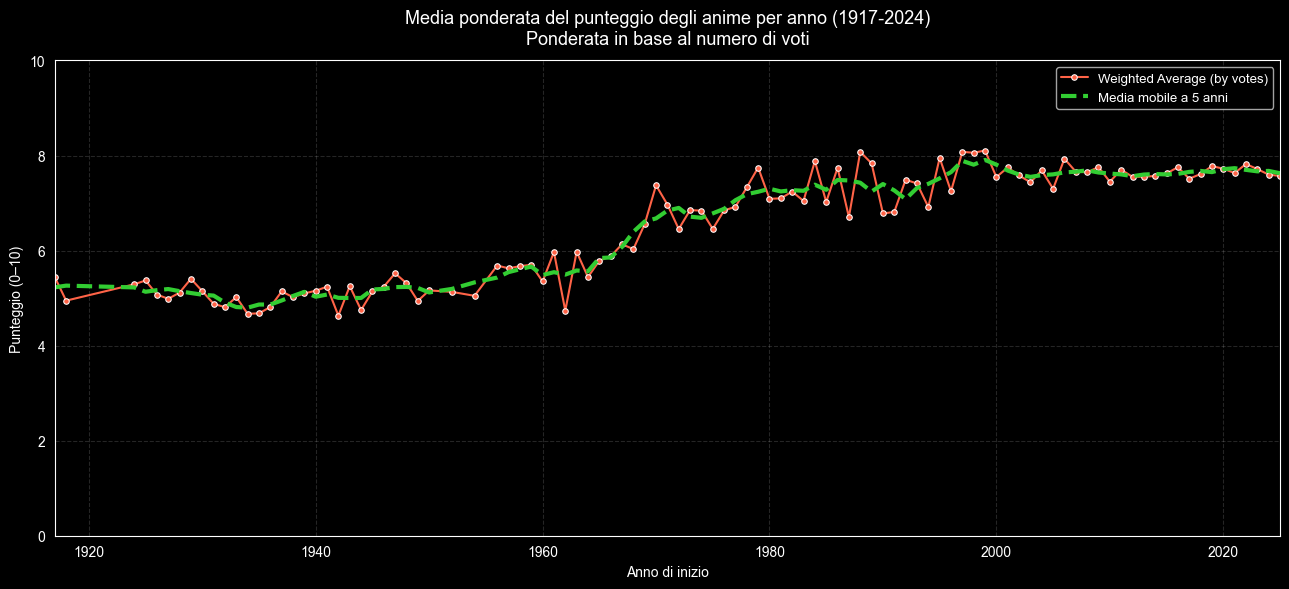

In [8]:
details = df_details.copy()
# filtro per il calcolo della media pesata
df_weighted = details[details['score'].notna() &details['scored_by'].notna() &(details['scored_by'] > 0) &details['year'].notna()].copy()
# limitiamo l'analisi agli anni con dati storicamnete rilevanti
df_weighted = df_weighted[df_weighted['year'] >= 1917]
# calcolo di media dei punteggi, totale dei voti, numero di anime rilasciati
year_weighted = df_weighted.groupby('year', group_keys=False).apply(
    lambda x: pd.Series({
        'weighted_mean': (x['score'] * x['scored_by']).sum() / x['scored_by'].sum(),
        'total_votes': x['scored_by'].sum(),
        'anime_count': len(x)
    }),
    include_groups=False).reset_index()
# ordina per sicurezza
year_weighted = year_weighted.sort_values('year')
# calcoliamo una media mobile centrata su 5 anni per rendere il trend più leggibile
year_weighted['rolling_weighted'] = year_weighted['weighted_mean'].rolling(window=5, center=True, min_periods=2).mean()
# visualizzazione
plt.figure(figsize=(13, 6))
# linea principale: media pesata
sns.lineplot(data=year_weighted,x='year',y='weighted_mean',color='tomato',linewidth=1.5,marker='o',markersize=4,label='Weighted Average (by votes)')
# media mobile
plt.plot(year_weighted['year'], year_weighted['rolling_weighted'],color='limegreen',linewidth=3,linestyle='--',label='Media mobile a 5 anni')
plt.title("Media ponderata del punteggio degli anime per anno (1917-2024)\nPonderata in base al numero di voti",fontsize=13,pad=12)
plt.xlabel("Anno di inizio")
plt.ylabel("Punteggio (0–10)")
# limiti degli assi per una scala coerente
plt.xlim(year_weighted['year'].min(), year_weighted['year'].max())
plt.ylim(0, 10)

plt.grid(True, alpha=0.15, linestyle='--')
plt.legend(fontsize=9.5)
plt.tight_layout()
plt.show()

Il grafico mostra l’andamento del punteggio medio degli anime dal 1917 al 2024, calcolato come media pesata sul numero di voti, così da dare maggiore importanza ai titoli più rilevanti per il pubblico.

Nei primi decenni la qualità media si mantiene su valori bassi e stabili, riflettendo una fase iniziale e sperimentale dell’industria. A partire dagli anni ’60 si osserva invece una crescita progressiva e significativa, in parallelo allo sviluppo dell’anime moderno e al consolidamento degli studi di animazione.

Dagli anni ’90 in poi, il punteggio medio raggiunge valori elevati e tende a stabilizzarsi, come evidenziato dalla media mobile a 5 anni. Questo suggerisce che, nonostante l’aumento della produzione, la qualità percepita dagli utenti rimane costante nel tempo, indicando una fase di maturità dell’industria anime.
> **Nota sui dati:** I decenni precedenti al 1960 presentano spesso 1–3 anime per anno e meno di 1.000 voti totali: le medie di quei periodi sono basate su campioni molto ridotti e vanno interpretate con cautela. La media mobile a 5 anni aiuta ad attenuare questi picchi isolati.


### I generi più prodotti sono anche quelli più amati dai fan?

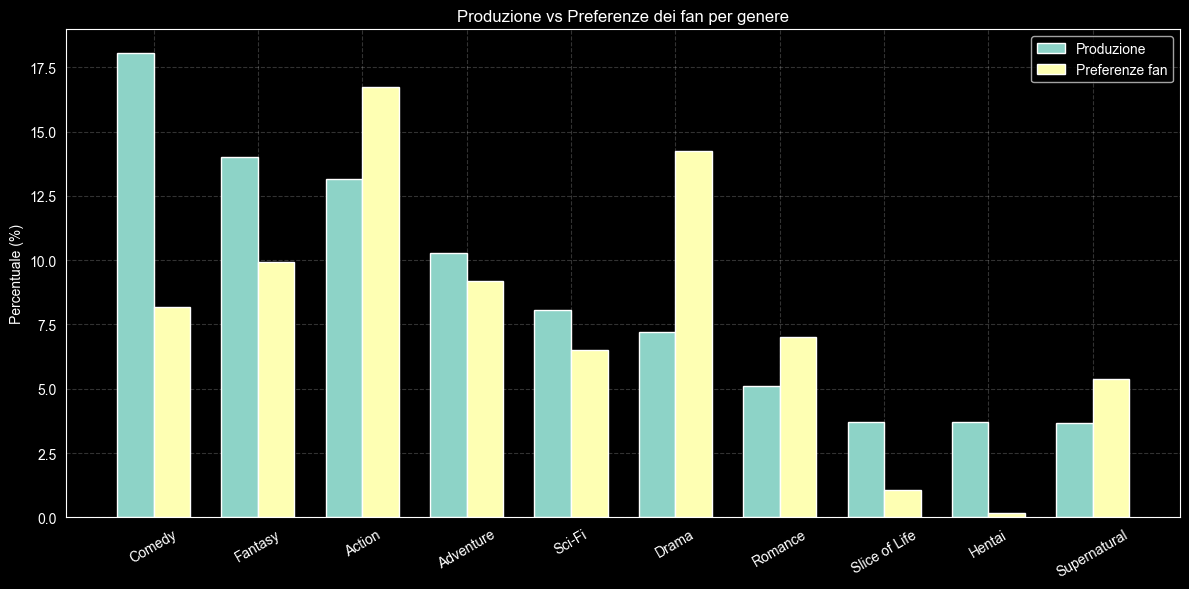

In [9]:
details = df_details.copy().dropna(subset=['genres'])
# converte la colonna generi da stringa in lista
details['genres'] = details['genres'].apply(utils.parse_genres)
# ogni genere diventa una riga separata
genres_df = details.explode('genres')
# copia il dataframe dei preferiti
favs = df_favs[df_favs['fav_type'] == 'anime'].copy()
# quante volte ogni genre appare nella produzione totale di anime
production = genres_df['genres'].value_counts()
# converetiamo i conteggi in percentuale sul totale della produzione
production_pct = production / production.sum() * 100
# unisce i preferiti degli utenti con i generi degli anime tramite mal id
favs_genres = pd.merge(favs, genres_df[['mal_id', 'genres']], on='mal_id', how='inner')
# conta quante volte ogni genre appare nei preferiti degli utenti
favs_count = favs_genres['genres'].value_counts()
# converte i conteggi dei preferiti in percentuale
favs_pct = favs_count / favs_count.sum() * 100
# crea un dataframe con le due percentuali affiancate per ogni genere
compare = pd.DataFrame({'Production (%)': production_pct, 'Fan Preferences (%)': favs_pct}).dropna()
# ordina per produzione decresente e prende i top 10
compare = compare.sort_values('Production (%)', ascending=False).head(10)
# array di poszione numeriche per posizionare le barre
x = np.arange(len(compare))
width = 0.35 # larghezza di ciasuna barra
# creazione figura
plt.figure(figsize=(12, 6))
plt.bar(x - width / 2, compare['Production (%)'], width, label='Produzione')
plt.bar(x + width / 2, compare['Fan Preferences (%)'], width, label='Preferenze fan', )
plt.xticks(x, compare.index, rotation=30)
plt.ylabel("Percentuale (%)")
plt.title("Produzione vs Preferenze dei fan per genere")
plt.legend()
plt.grid(True, alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

Il grafico mette a confronto la percentuale di produzione degli anime per genere con le preferenze dichiarate dai fan, evidenziando in modo immediato le aree di allineamento e quelle di discrepanza. Alcuni generi, come **Comedy** e **Fantasy**, mostrano una produzione molto elevata, ma non sempre corrispondono a un interesse dei fan altrettanto forte, suggerendo una sovraofferta rispetto alla domanda.
Al contrario, generi come Drama o Romance mostrano il divario opposto: i fan li preferiscono più di quanto vengono prodotti. In altri casi, come _Hentai_ o _Slice of Life_, la produzione risulta superiore alle preferenze, mentre generi come Supernatural mostrano un rapporto più armonico tra offerta e gradimento.
Nel complesso, il grafico racconta una dinamica interessante: l’industria tende a investire maggiormente nei generi più versatili e commerciali, mentre le preferenze dei fan risultano più distribuite e talvolta orientate verso generi meno rappresentati. Questa differenza tra produzione e domanda offre uno spunto utile per comprendere come il mercato anime si adatti o talvolta non si adatti alle aspettative del pubblico.


## 3. LE ORIGINI NARRATIVE DEGLI ANIME

### Da dove nascono gli anime

In [10]:
details = df_details.copy()
# rimuovo valori nulli e cateogie non informative
details = details[(details['source'].notna()) & (details['source'] != 'Unknown') & (details['source'] != 'Other')]
# normalizzazione testo
details['source'] = details['source'].str.strip().str.title()
# conteggio per categoria
source_counts = details['source'].value_counts().reset_index()
# rinomina colonne
source_counts.columns = ['source', 'count']
# creazione treemap
fig = px.treemap(
    source_counts,
    path=['source'],
    values='count',
    color='count',
    color_continuous_scale='Blues',
    title='Da dove nascono gli anime?',
)
fig.update_traces(
    textinfo='label+value+percent root',
    textfont_size=14,
    hovertemplate='<b>%{label}</b><br>Anime: %{value:,}<br>%{percentRoot:.1%}<extra></extra>'
)
fig.update_layout(height=520, margin=dict(t=50, l=10, r=10, b=10),
                  coloraxis_colorbar=dict(title='N. anime'))
fig.show()

Il grafico mostra la distribuzione delle principali **fonti di ispirazione** degli anime, evidenziando da quali media o opere originali nasce la produzione animata giapponese.

Il dato più evidente è la **forte predominanza delle opere Original**, che rappresentano la quota maggiore. Questo suggerisce che l’industria anime mantiene una notevole capacità creativa autonoma, producendo contenuti non direttamente derivati da altri media.

Subito dopo emergono gli adattamenti da **Manga**, che confermano il ruolo centrale di questo medium come serbatoio narrativo per l’animazione giapponese. Manga e anime risultano quindi profondamente interconnessi, sia dal punto di vista artistico che industriale.

Le altre categorie (come **Light Novel**, **Game**, **Visual Novel** e **Web Manga**) hanno una presenza più contenuta ma significativa, indicando una crescente tendenza alla contaminazione tra media diversi. Questo fenomeno riflette l’evoluzione del consumo culturale, sempre più crossmediale.

Nel complesso, il grafico racconta un’industria che combina **creatività originale** e **adattamento strategico**, bilanciando innovazione e sicurezza commerciale.
> **Nota sui dati:** Il 14,2 % degli anime (4.120 titoli) ha fonte classificata come "Unknown", "Other" o non disponibile ed è escluso dal grafico. La distribuzione rappresenta l'85,8 % del catalogo.


#Qualità e popolarità nel tempo: un panorama per tipo di produzione

In [11]:
details = df_details.copy()
# elimina le righe senza anno, score, membri o tipo senza questi campi il dato è inutilizzabile
details = details.dropna(subset=['year', 'score', 'members', 'type'])
# filtro temporale
details = details[(details['year'] >= 1960) & (details['year'] <= 2024)]
# soglia minima di popolarità: esclude titoli quasi sconosciuti che distorcono i conteggi
details = details[details['members'] >= 500]
# tipi di produzione principali esclude categorie residuali con pochi titoli
main_types = ['TV', 'Movie', 'OVA', 'Special', 'ONA']
details = details[details['type'].isin(main_types)]
# converte year in intero puro per usarlo come animation_frame
details['year'] = details['year'].astype(int)
# conta quanti anime ci sono per ogni combinazione anno+tipo
counts = (details.groupby(['year', 'type']).size().reset_index(name='count'))
# crea tutte le combinazioni anno×tipo possibili — così gli anni con zero anime non spariscono dal grafico
all_combinations = pd.MultiIndex.from_product([counts['year'].unique(), main_types], names=['year', 'type'])
# reindex con fill_value=0 garantisce che ogni frame abbia sempre tutte e 5 le barre
counts = (counts.set_index(['year', 'type']).reindex(all_combinations, fill_value=0).reset_index())
# ordina per anno poi per tipo: plotly legge i frame nell'ordine in cui trova i dati
counts = counts.sort_values(['year', 'type'])
# costruisce il bar chart animato — animation_frame crea un frame per ogni anno
fig = px.bar(
    counts,
    x='type',
    y='count',
    color='type',
    animation_frame='year',
    text='count',
    labels={'type': 'Tipo', 'count': 'Numero di anime'},
    title='Produzione anime per tipo: anno per anno (1960–2024)',
    color_discrete_sequence=px.colors.qualitative.Bold,
    range_y=[0, counts['count'].max() * 1.15],
    category_orders={'type': main_types},
)

# posiziona i valori testo fuori dalla barra per leggibilità
fig.update_traces(textposition='outside', textfont_size=13)
# layout generale
fig.update_layout(
    height=520,
    showlegend=False,
    plot_bgcolor='rgba(248,248,248,1)',
    paper_bgcolor='rgba(0,0,0,0)',
    title_font_size=18,
    xaxis_title='Tipo',
    yaxis_title='Numero di anime',
    hoverlabel=dict(bgcolor='white', font_size=12),
)
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=True, gridcolor='rgba(220,220,220,1)')
# rallenta leggermente l'animazione automatica per dare il tempo di leggere ogni frame
fig.layout.updatemenus[0].buttons[0].args[1]['frame']['duration'] = 500
fig.layout.updatemenus[0].buttons[0].args[1]['transition']['duration'] = 250

fig.show()

## 4. POPOLARITA' E IMPATTO CULTURALE

### In quali anni emergono gli anime più popolari?

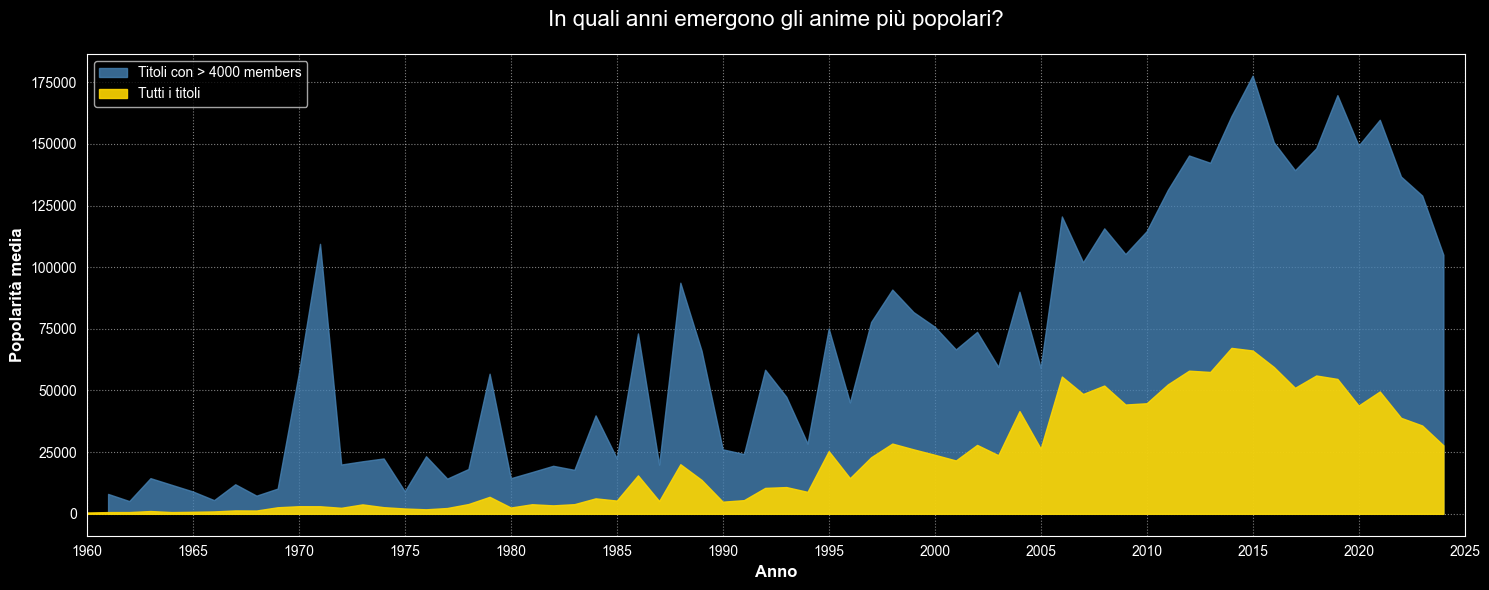

In [12]:
details = df_details.copy()
# media popolarità per anno su tutti i titoli
all_titles = (df_details.groupby('year')['members'].mean().reset_index().rename(columns={'members': 'avg_members'}))
# filtro temporale
all_titles = all_titles[(all_titles['year'] >= 1960) & (all_titles['year'] <= 2024)]
# filtro dati: solo anime con più 5000 membri
popular = (df_details[df_details['members'] > 5000].groupby('year')['members'].mean().reset_index().rename(columns={'members': 'avg_members'}))
# filtro temporale
popular = popular[(popular['year'] >= 1960) & (popular['year'] <= 2024)]
# grafico
plt.figure(figsize=(15, 6))
plt.fill_between(popular['year'], popular['avg_members'], color='steelblue', alpha=0.8, label='Titoli con > 4000 members')
plt.fill_between(all_titles['year'], all_titles['avg_members'], color='gold', alpha=0.9, label='Tutti i titoli')
plt.title('In quali anni emergono gli anime più popolari?', fontsize=16, pad=20)
plt.xlabel('Anno', fontsize=12, fontweight='bold')
plt.ylabel('Popolarità media', fontsize=12, fontweight='bold')
plt.xlim(1960, 2024)
plt.xticks(range(1960, 2026, 5))
plt.grid(linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Il grafico mostra l’andamento della popolarità degli anime più seguiti nel corso di diversi decenni, misurata attraverso il numero medio di membri. La linea evidenzia un percorso irregolare ma significativo: nei primi anni la popolarità rimane contenuta, con oscillazioni limitate e valori relativamente bassi.
A partire dagli anni ’70 compaiono i primi picchi, seguiti da un nuovo aumento verso la fine degli anni ’80, segno di un interesse crescente e di titoli che iniziano a raggiungere un pubblico più ampio. Tuttavia, è dall’inizio degli anni 2000 che la curva cambia ritmo in modo evidente: la popolarità cresce rapidamente, raggiungendo il suo massimo tra la metà e la fine degli anni 2010.
Dopo questo periodo di forte espansione, la linea mostra una diminuzione verso il 2020, suggerendo una fase di rallentamento dopo anni di crescita intensa. Nonostante ciò, i valori rimangono comunque molto più alti rispetto alle decadi precedenti, indicando un livello di interesse complessivo ancora elevato.
Nel complesso, il grafico racconta una storia di progressiva affermazione: da un fenomeno di nicchia, la popolarità degli anime più seguiti cresce fino a diventare un elemento centrale della cultura contemporanea, con cicli di espansione e assestamento che riflettono l’evoluzione del pubblico e dell’industria.
> **Nota sui dati:** La soglia di 4.000 membri è arbitraria e include il 34,4 % del catalogo. Gli anni 1955–1960 in cui nessun anime supera tale soglia vengono rappresentati come 0: non come dato mancante, ma come assenza di titoli sufficientemente seguiti in quel periodo.

## Distribuzione dei voti per anime

Le valutazioni non sono solo medie: ogni anime ha una distribuzione di voti che racconta molto di più. Un anime polarizzante raccoglie sia 1 che 10; uno consistente ha voti concentrati attorno a 8–9. La distribuzione rivela la qualità percepita e l'unanimità del giudizio

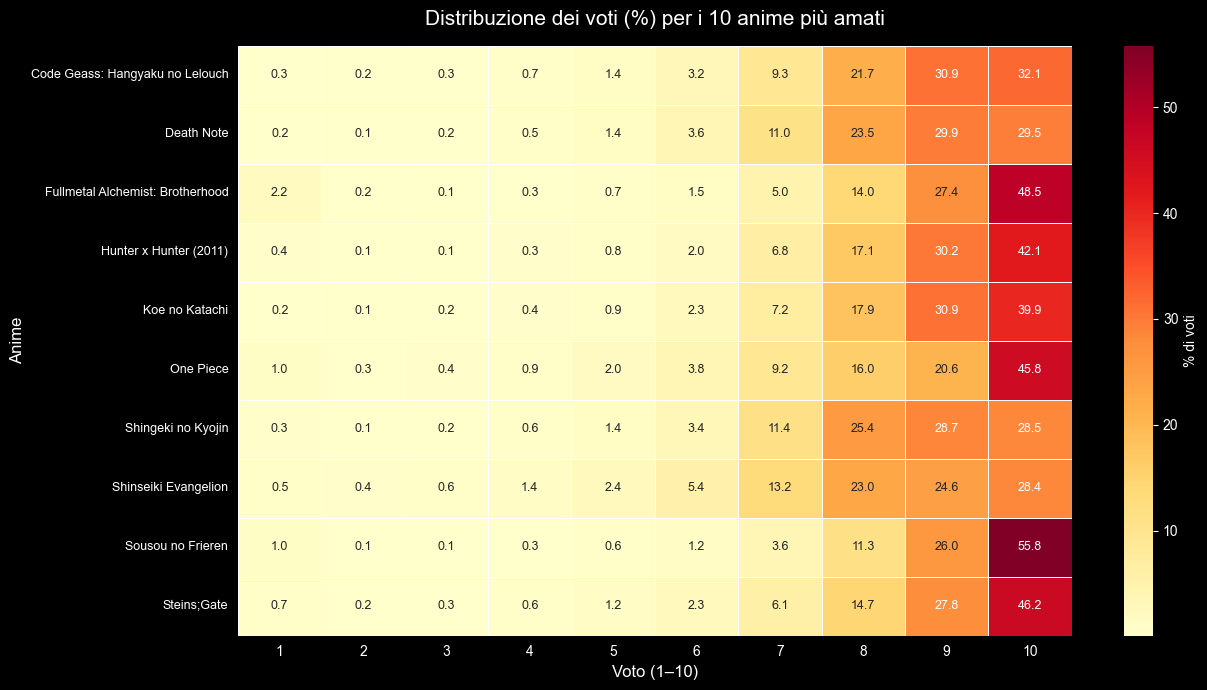

In [13]:
stats = df_stats.copy()
favs = df_favs[df_favs["fav_type"] == "anime"].copy()
# solo i preferiti con anime valido
valid_mal_ids = df_details["mal_id"].unique()
filtered_favs = favs[favs["mal_id"].isin(valid_mal_ids)]
# top 10
top10_ids  = filtered_favs["mal_id"].value_counts().head(10).index
# costruisco i nomi delle colonne dei voti da 1 a 10
score_cols = [f"score_{i}_votes" for i in range(1, 11)]
# solo le righe dei top 10 con le colonne dei voti
top_stats = stats[stats["mal_id"].isin(top10_ids)][["mal_id"] + score_cols].copy()
# merge , aggiunge il titolo
top_stats = pd.merge(top_stats, df_details[["mal_id", "title"]], on="mal_id", how="left")
# normalizza a percentuale per riga
top_stats[score_cols] = (top_stats[score_cols].div(top_stats[score_cols].sum(axis=1), axis=0) * 100)
#heatmap
heatmap_data = top_stats.set_index("title")[score_cols].copy()
heatmap_data.columns = list(range(1, 11))
fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(heatmap_data,annot=True, fmt=".1f", cmap="YlOrRd",linewidths=0.5, ax=ax, cbar_kws={"label": "% di voti"},annot_kws={"size": 9})
ax.set_title("Distribuzione dei voti (%) per i 10 anime più amati", fontsize=15, pad=15)
ax.set_xlabel("Voto (1–10)", fontsize=12)
ax.set_ylabel("Anime", fontsize=12)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

La heatmap non racconta solo chi ha vinto, ma come ha vinto.

Il dato più immediato è che quasi tutti i titoli concentrano i propri voti nella fascia alta: 8, 9 e 10. Non è una sorpresa stiamo parlando dei 10 anime più amati della piattaforma. Ma le differenze tra loro sono rivelatrici.

Sousou no Frieren si distingue nettamente: il 55,8% degli utenti gli ha dato un voto 10 e il 93,1% ha votato tra 8 e 10. È l'anime con il consenso più ampio e uniforme del gruppo  un fenomeno recente che ha conquistato quasi tutti. Vicino a lui troviamo Fullmetal Alchemist: Brotherhood (89,9% tra 8 e 10) e Hunter x Hunter (2011) (89,4%).

All'estremo opposto, Neon Genesis Evangelion è l'unico titolo dove la colonna del 10 non domina e dove i voti bassi sono visibilmente più presenti rispetto agli altri. Solo il 76% dei voti cade nella fascia 8–10. È un'opera che divide: chi la ama la considera un capolavoro, chi la trova insoddisfacente lo dice chiaramente.

Death Note e Shingeki no Kyojin mostrano un profilo simile tra loro: entrambi con il picco a 9 anziché 10, e una distribuzione leggermente più "piatta" verso i voti centrali  segnale di un pubblico ampio ma non unanime, forse composto anche da spettatori arrivati alla serie per il clamore mediatico più che per passione diretta.
Un'anomalia interessante riguarda Fullmetal Alchemist: Brotherhood: ha il 2,2% di voti all'1, la percentuale più alta del gruppo per questo punteggio. Pur essendo tra i titoli più amati in assoluto, raccoglie anche più "1" degli altri probabilmente voti di protesta o di utenti che non ne condividono la fama.

### One Piece: qualità percepita e popolarità tra gli utenti


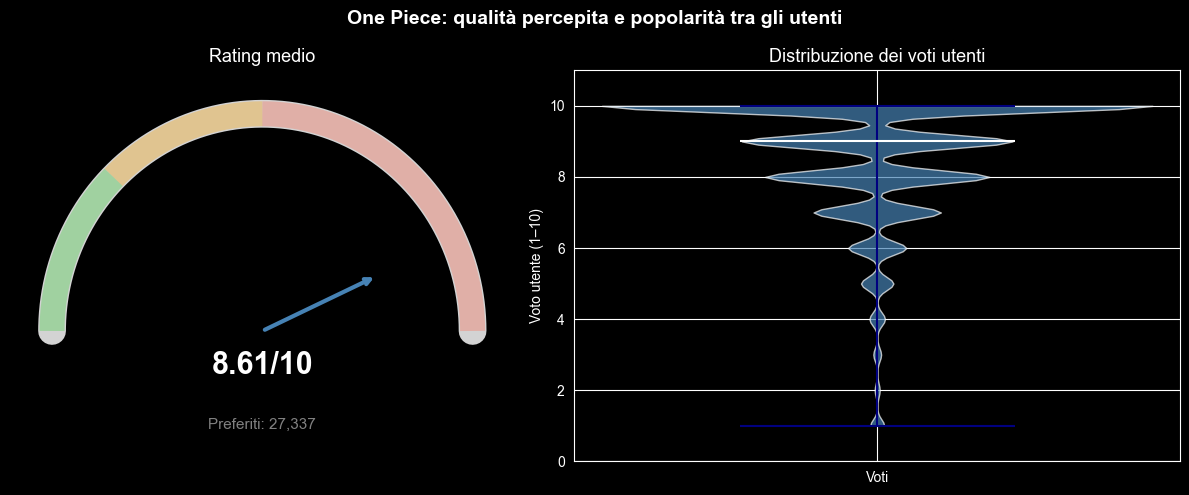

In [14]:
details = df_details.copy()
ratings = df_ratings.copy()
anime_title = 'One Piece'
mal_id = details[details['title'] == anime_title]['mal_id'].iloc[0]
# prendo solo i voti validi
anime_ratings = ratings[(ratings['anime_id'] == mal_id) & (ratings['score'] > 0)]['score']
# media dei voti
avg_user_rating = anime_ratings.mean()
# quanti utenti hanno messo One Piece nei preferiti
fav_count = favs[favs['mal_id'] == mal_id].shape[0]
fig = plt.figure(figsize=(12, 5))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.2])
#gauge
ax0 = fig.add_subplot(gs[0])
theta = np.linspace(0, np.pi, 300)
ax0.plot(np.cos(theta), np.sin(theta), color='lightgray', lw=20, solid_capstyle='round')

for start, end, color in [
    (0,    0.5,  '#ff634750'),
    (0.5,  0.75, '#ffa50050'),
    (0.75, 1.0,  '#32cd3250')
]:
    t = np.linspace(start * np.pi, end * np.pi, 100)
    ax0.plot(np.cos(t), np.sin(t), lw=18, color=color, solid_capstyle='butt')
angle = np.pi * (1 - avg_user_rating / 10)
ax0.annotate('', xy=(0.6 * np.cos(angle), 0.6 * np.sin(angle)), xytext=(0, 0),arrowprops=dict(arrowstyle='->', color='steelblue', lw=3))
ax0.text(0, -0.2,  f'{avg_user_rating:.2f}/10', ha='center', fontsize=22, fontweight='bold')
ax0.text(0, -0.45, f'Preferiti: {fav_count:,}', ha='center', fontsize=11, color='gray')
ax0.set_xlim(-1.2, 1.2)
ax0.set_ylim(-0.6, 1.2)
ax0.axis('off')
ax0.set_title('Rating medio', fontsize=13)
#Violin
ax1 = fig.add_subplot(gs[1])
parts = ax1.violinplot(anime_ratings, positions=[1], showmedians=True, showextrema=True)
parts['bodies'][0].set_facecolor('steelblue')
parts['bodies'][0].set_alpha(0.7)
parts['cmedians'].set_color('white')
parts['cbars'].set_color('navy')
parts['cmins'].set_color('navy')
parts['cmaxes'].set_color('navy')
ax1.set_xticks([1])
ax1.set_xticklabels(['Voti'])
ax1.set_ylabel('Voto utente (1–10)')
ax1.set_ylim(0, 11)
ax1.set_title('Distribuzione dei voti utenti', fontsize=13)
plt.suptitle('One Piece: qualità percepita e popolarità tra gli utenti', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Questo grafico analizza il caso di **One Piece**, mettendo a confronto la **qualità percepita dagli utenti** (rating medio) e la **popolarità**, misurata tramite il numero di preferenze (favs).

Il primo grafico evidenzia come One Piece presenti una popolarità estremamente elevata, normalizzata su una scala comparabile con il rating. Al contrario, il rating medio degli utenti risulta più moderato. Questo squilibrio suggerisce che la popolarità non dipende esclusivamente dal giudizio medio, ma anche da fattori come la longevità della serie, l’affezione emotiva del pubblico e l’impatto culturale nel tempo.

Il secondo grafico mostra la **distribuzione dei voti degli utenti**. Si osserva una forte concentrazione di voti alti (8–10), accompagnata però da una presenza significativa di voti bassi. Questo fenomeno è tipico delle opere molto popolari: attirano un pubblico ampio e diversificato, generando valutazioni più polarizzate.

Nel complesso, One Piece emerge come un esempio emblematico di come un anime possa essere **massicciamente seguito e amato**, pur non avendo un consenso uniforme sul piano della valutazione numerica.


## Raccomandazioni e distribuzione dei voti

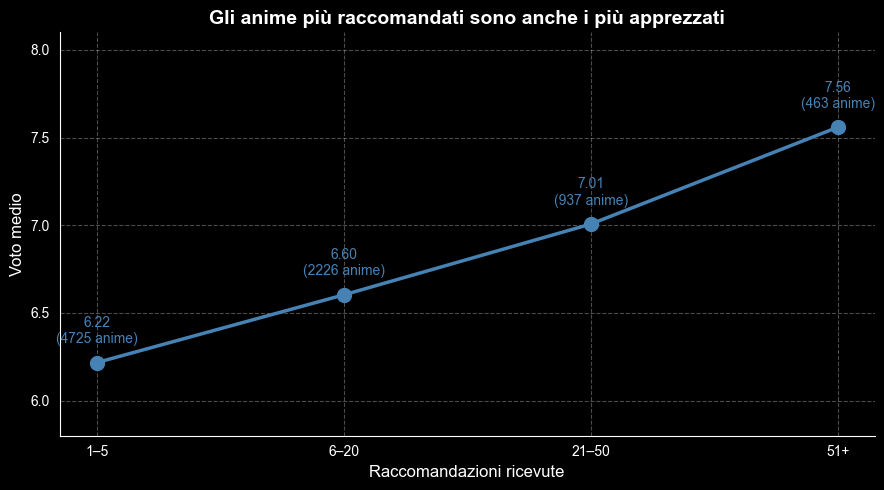

In [15]:
recs = df_recommendations.copy()
ratings_clean = df_ratings.copy()
# raccomandazioni ricevute per anime
rec_count = recs['recommendation_mal_id'].value_counts().reset_index()
rec_count.columns = ['anime_id', 'n_recs']
# voto medio per anime (almeno 100 voti)
anime_scores = (ratings_clean[ratings_clean['score'] > 0].groupby('anime_id')['score'].agg(avg_score='mean', n_ratings='count').reset_index())
anime_scores = anime_scores[anime_scores['n_ratings'] >= 100]
# unione e fasce
data = anime_scores.merge(rec_count, on='anime_id', how='inner')
bins = [0, 5, 20, 50, float('inf')]
tier_labels = ['1–5', '6–20', '21–50', '51+']
data['rec_tier'] = pd.cut(data['n_recs'], bins=bins, labels=tier_labels)
# voto medio e conteggio per fascia
summary = ( data.groupby('rec_tier', observed=True)['avg_score'].agg(media='mean', n_anime='count').reset_index())
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(summary['rec_tier'], summary['media'], marker='o', linewidth=2.5,markersize=10, color='steelblue')

for _, row in summary.iterrows():
    ax.annotate(
        f"{row['media']:.2f}\n({int(row['n_anime'])} anime)",
        xy=(row['rec_tier'], row['media']),
        xytext=(0, 14), textcoords='offset points',
        ha='center', fontsize=10, color='steelblue'
    )

ax.set_ylim(5.8, 8.1)
ax.set_xlabel('Raccomandazioni ricevute', fontsize=12)
ax.set_ylabel('Voto medio', fontsize=12)
ax.set_title('Gli anime più raccomandati sono anche i più apprezzati', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, linestyle='--')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


La linea sale in modo costante: gli anime che ricevono più raccomandazioni ottengono in media voti più alti.

Nella fascia *1–5 raccomandazioni* il voto medio si ferma a **6.22**, mentre gli anime con *51 o più raccomandazioni* raggiungono **7.56**. Non è un caso: gli utenti tendono a consigliare ciò che li ha davvero colpiti, e i titoli che rimbalzano di più tra le raccomandazioni sono proprio quelli che la community riconosce come di qualità.

In altre parole, le raccomandazioni funzionano come un segnale di qualità collettivo: più un anime viene suggerito, più è probabile che valga davvero la pena guardarlo.

## 5. I PERSONAGGI

Dopo aver osservato gli anime più popolari, il passo successivo è capire **dove si concentra l’attenzione dei fan**.

### Personaggi principali e secondari: quantità e notorietà a confronto

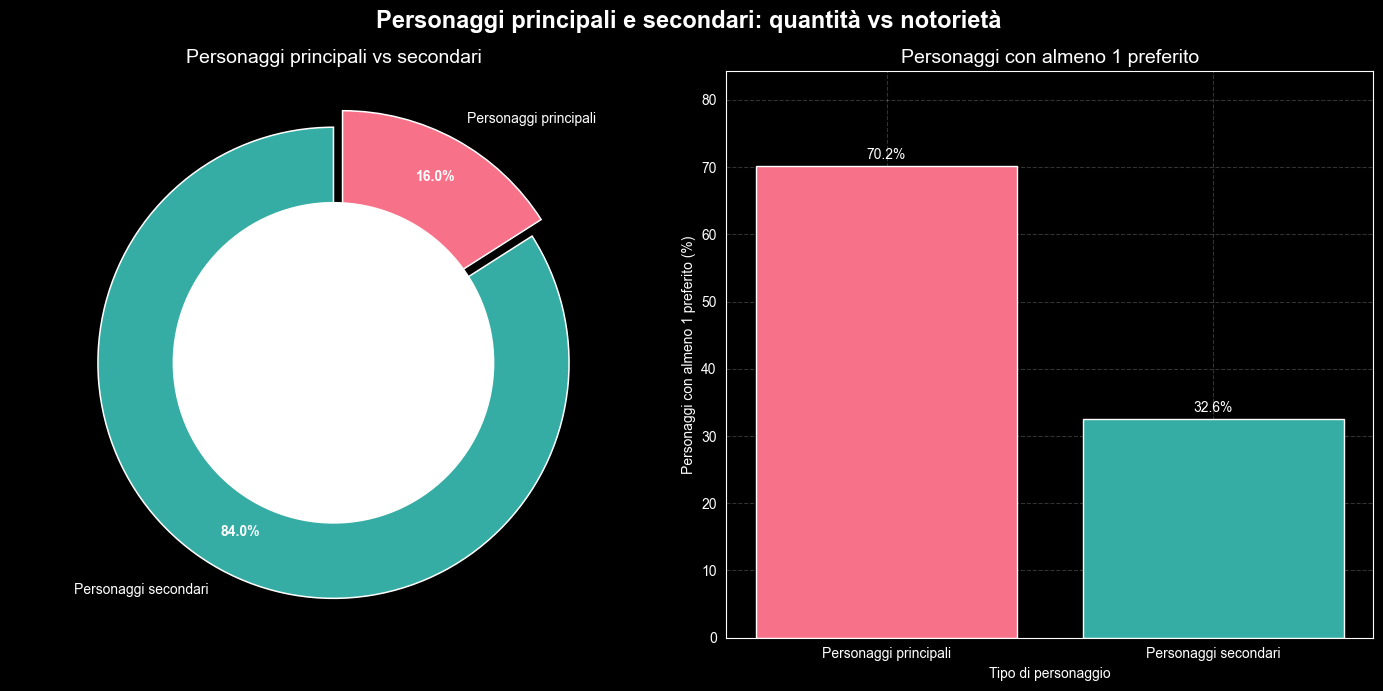

In [16]:
# preparazione dati
character_popularity = (
    df_characters_anime_works
    .loc[lambda df: df["role"].isin(["Main", "Supporting"]), ["character_mal_id", "role"]]
    .drop_duplicates()
    .groupby("character_mal_id")
    .filter(lambda x: x["role"].nunique() == 1)
    .drop_duplicates("character_mal_id")
    .merge(df_characters[["character_mal_id", "favorites"]], on="character_mal_id")
)
labels = {"Main": "Personaggi principali", "Supporting": "Personaggi secondari"}
order = ["Personaggi principali", "Personaggi secondari"]
character_popularity["role_group"] = character_popularity["role"].replace(labels)
character_popularity["has_favorites"] = character_popularity["favorites"] > 0
# tabelle
main_support_table = (character_popularity.groupby("role_group")["character_mal_id"].nunique().reindex(order))
popularity_table = (character_popularity.groupby("role_group").agg(total=("character_mal_id", "nunique"),with_favourites=("has_favorites", "sum")).reindex(order))
popularity_table["share"] = (popularity_table["with_favourites"] / popularity_table["total"] * 100).round(1)
# grafico
plt.figure(figsize=(14, 7))
colors = sns.color_palette("husl", 2)
plt.subplot(1, 2, 1)
wedges, texts, autotexts = plt.pie(
    main_support_table,
    labels=main_support_table.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=colors,
    explode=[0.08, 0],
    pctdistance=0.82,
    wedgeprops={"edgecolor": "white", "linewidth": 1.1}
)
for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
plt.gca().add_artist(plt.Circle((0, 0), 0.68, fc="white"))
plt.title("Personaggi principali vs secondari", fontsize=14)
plt.axis("equal")
plt.subplot(1, 2, 2)
bars = plt.bar(popularity_table.index, popularity_table["share"], color=colors)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 1, f"{h:.1f}%", ha="center", fontsize=10)
plt.title("Personaggi con almeno 1 preferito", fontsize=14)
plt.xlabel("Tipo di personaggio")
plt.ylabel("Personaggi con almeno 1 preferito (%)")
plt.ylim(0, popularity_table["share"].max() * 1.2)
plt.grid(True, alpha=0.2, linestyle='--')
plt.suptitle("Personaggi principali e secondari: quantità vs notorietà", fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()

l grafico racconta due storie parallele sui personaggi anime.

A sinistra, i numeri: solo il 16% dei personaggi sono protagonisti, mentre l'84% sono figure secondarie. L'universo degli anime è **popolato principalmente da personaggi di contorno**, necessari a costruire il mondo narrativo intorno ai protagonisti.

A destra, la notorietà: il 70% dei personaggi principali ha ricevuto almeno un preferito dagli utenti, contro solo il 32.6% dei secondari. Nonostante siano in minoranza, **i protagonisti riescono quasi sempre a lasciare il segno.**

I personaggi secondari possono essere più numerosi, ma i **protagonisti tendono ad avere maggiore visibilità e a costruire un legame più diretto con i fan**.

## 6. I DOPPIATORI E LINGUE: LE VOCI DIETRO GLI ANIME

Un personaggio non vive solo attraverso il disegno o la storia: **vive anche attraverso la voce**.
Il doppiaggio dà identità ai personaggi, li rende riconoscibili e permette agli anime di arrivare a pubblici diversi.

## Quanti doppiatori hanno gli anime più amati?

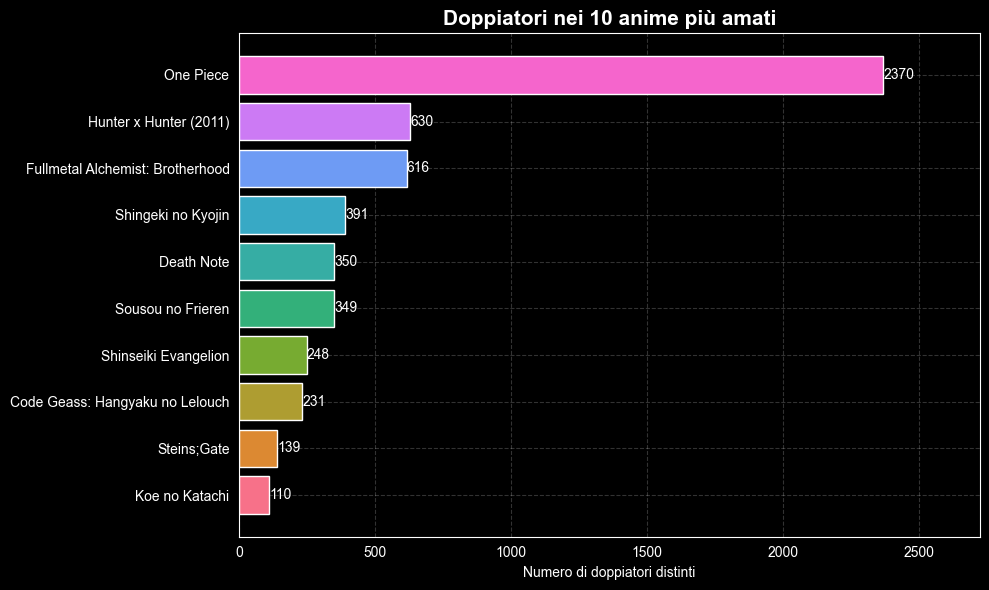

In [17]:
details = df_details.copy()
favs = df_favs[df_favs["fav_type"] == "anime"].copy()
voice_works = df_person_voice_works.copy()

top_anime_voice = (
    favs[favs["mal_id"].isin(details["mal_id"])]["mal_id"]
    .value_counts()
    .head(10)
    .reset_index(name="fav_count")
    .rename(columns={"index": "mal_id"})
    .merge(details[["mal_id", "title"]], on="mal_id")
    .merge(
        voice_works.groupby("anime_mal_id")["person_mal_id"]
        .nunique()
        .reset_index(name="distinct_voice_actors"),
        left_on="mal_id",
        right_on="anime_mal_id",
        how="left"
    )
    .fillna({"distinct_voice_actors": 0})
    .sort_values("distinct_voice_actors")
)

top_anime_voice["distinct_voice_actors"] = top_anime_voice["distinct_voice_actors"].astype(int)

plt.figure(figsize=(10, 6))
colors = sns.color_palette("husl", len(top_anime_voice))

bars = plt.barh(
    top_anime_voice["title"],
    top_anime_voice["distinct_voice_actors"],
    color=colors
)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 1, bar.get_y() + bar.get_height()/2, int(width), va="center", fontsize=10)

plt.title("Doppiatori nei 10 anime più amati", fontsize=15, fontweight="bold")
plt.xlabel("Numero di doppiatori distinti")
plt.ylabel("")
plt.grid(True, alpha=0.2, linestyle='--')
plt.xlim(0, top_anime_voice["distinct_voice_actors"].max() * 1.15)
plt.tight_layout()
plt.show()


Questo grafico rappresenta  quanti doppiatori hanno le anime più amate (prese dal grafico Top 10 Anime più amate)).
Il numero di doppiatori aiuta a vedere la **complessità produttiva dietro gli anime più popolari**.

Il dato più evidente è che **One Piece** supera di gran lunga tutti gli altri: trattandosi di una serie lunghissima e con un cast enorme, ha richiesto centinaia di voci nel corso degli anni. Al contrario, anime come Hunter x Hunter o Steins;Gate (pur essendo tra i più amati) hanno un numero di doppiatori molto più contenuto confermando che **la popolarità non dipende dalla grandezza del cast**.

Dopo aver visto quali anime richiedono il maggior numero di voci, il passo successivo è osservare il fenomeno dal punto di vista opposto: non più gli anime, ma i singoli doppiatori, per capire quali professionisti hanno interpretato il maggior numero di personaggi distinti.

## Top 10 doppiatori per personaggi distinti doppiati

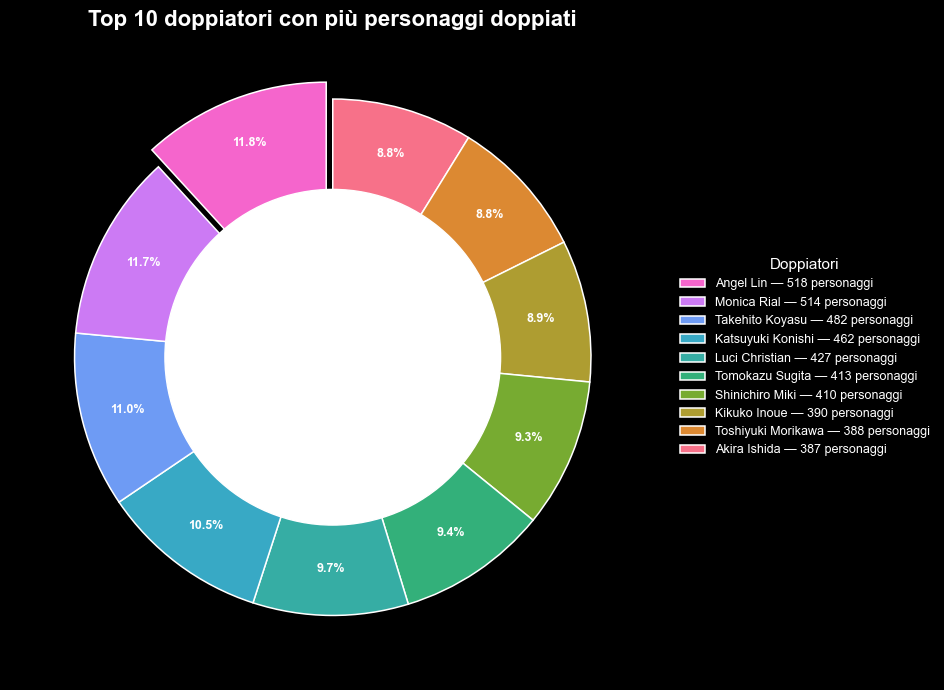

In [18]:
# preparazione dati
voice_works = df_person_voice_works.copy()
person_details = df_person_details.copy()

top_voice_actors = (
    voice_works.groupby("person_mal_id")["character_mal_id"]
    .nunique()
    .reset_index(name="characters")
    .sort_values("characters", ascending=False)
    .head(10)
    .merge(person_details[["person_mal_id", "name"]], on="person_mal_id", how="left")
    .sort_values("characters")
)

colors = sns.color_palette("husl", len(top_voice_actors))
explode = [0.07 if x == top_voice_actors["characters"].max() else 0
           for x in top_voice_actors["characters"]]

# grafico
plt.figure(figsize=(9, 7))

wedges, texts, autotexts = plt.pie(
    top_voice_actors["characters"],
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=colors,
    explode=explode,
    pctdistance=0.82,
    wedgeprops={"edgecolor": "white", "linewidth": 1.1}
)

for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
    t.set_fontsize(9)

plt.gca().add_artist(plt.Circle((0, 0), 0.65, fc="white"))

legend_labels = [f"{n} — {v} personaggi"
                 for n, v in zip(top_voice_actors["name"][::-1],
                                 top_voice_actors["characters"][::-1])]

plt.legend(wedges[::-1], legend_labels,
           title="Doppiatori", loc="center left",
           bbox_to_anchor=(1.02, 0.5), frameon=False,
           fontsize=9, title_fontsize=11)

plt.title("Top 10 doppiatori con più personaggi doppiati", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

l grafico mostra i 10 doppiatori giapponesi con il maggior numero di personaggi distinti
interpretati. Al primo posto si trova **Angel Lin, con oltre 518 personaggi doppiati** nell'arco
della sua carriera.

È interessante notare che questi numeri elevati spesso includono ruoli minori e
secondari: un singolo doppiatore può comparire in decine di anime diversi, spesso in
parti brevi, costruendo la propria esperienza nel tempo.

Il doppiaggio permette agli anime di superare i confini linguistici e raggiungere community diverse.

## Le lingue più doppiate

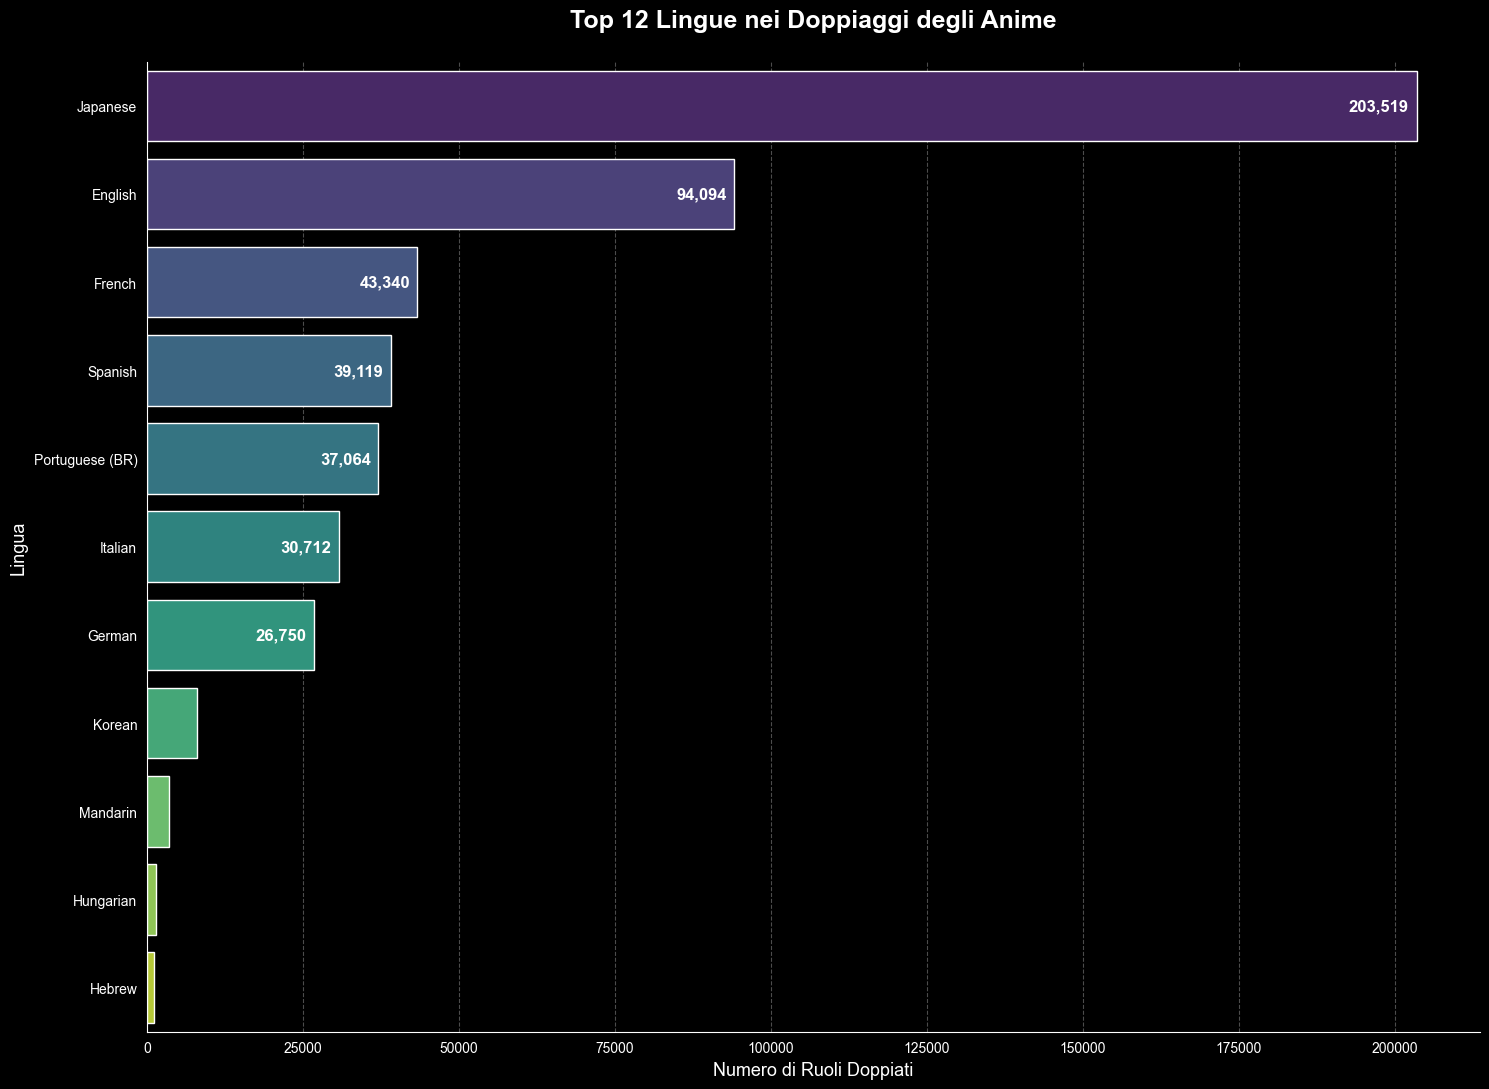

In [19]:
voice = df_person_voice_works.copy()
# preparazione dati
lang_stats = voice.groupby('language').agg(total_roles=('character_mal_id', 'count')).sort_values('total_roles', ascending=False)
# top 12 lingue
top12 = lang_stats.head(12).reset_index()
# figura
plt.figure(figsize=(15, 11))
ax = sns.barplot(data=top12,y='language',x='total_roles',palette='viridis')
plt.title('Top 12 Lingue nei Doppiaggi degli Anime',fontsize=18,fontweight='bold',pad=25)
plt.xlabel('Numero di Ruoli Doppiati', fontsize=13)
plt.ylabel('Lingua', fontsize=13)

for i, row in enumerate(top12.itertuples()):
    if row.total_roles > 10000:
        # Per barre lunghe
        ax.text(x = row.total_roles - 1200,y = i, s = f"{row.total_roles:,}",
            va = 'center',ha = 'right',fontsize = 12,color = 'white',fontweight = 'bold'
        )
    else:
        # Per barre corte
        ax.text(x = row.total_roles + 800,y = i,s = f"{row.total_roles:,}",
            va = 'center',ha = 'left',fontsize = 12,color = 'black',fontweight = 'bold'
        )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.grid(axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

Il grafico racconta qualcosa di semplice ma potente: gli anime non sono più un fenomeno solo giapponese.

Con 203.519 ruoli doppiati, il giapponese rimane la lingua dominante e rappresenta il 41,7% di tutti i ruoli presenti nel dataset. È la lingua d'origine, quella in cui ogni personaggio nasce e viene pensato. Ma è solo l'inizio.

L'inglese segue con oltre 94.000 ruoli  più della metà del giapponese confermando il ruolo degli Stati Uniti come primo grande mercato di esportazione. Il doppiaggio anglofono ha reso gli anime accessibili al pubblico occidentale già dagli anni Novanta, costruendo una fanbase enorme che oggi richiede nuove uscite doppiare quasi in contemporanea con il Giappone.

Quello che colpisce davvero è la forza del blocco europeo: francese (43.340), spagnolo (39.119), portoghese brasiliano (37.064), italiano (30.712) e tedesco (26.750) sommano insieme quasi 177.000 ruoli oltre il 36% del totale. L'Europa, trainata da Francia e Spagna, è diventata un polo fondamentale nell'industria del doppiaggio anime.

Il portoghese brasiliano merita un'attenzione specifica: con 37.064 ruoli supera l'italiano e si avvicina allo spagnolo, riflettendo la passione storica del Brasile per gli anime, dove Pokémon, Dragon Ball e Cavalieri dello Zodiaco hanno segnato intere generazioni.
Più in basso nella classifica compaiono coreano (7.981) e mandarino (3.529), che rappresentano il doppiaggio asiatico non giapponese.

## 7. Community anime nel mondo

Gli anime non crescono soltanto come produzione: crescono anche attraverso le persone che li guardano, li commentano, li valutano e li inseriscono nelle proprie liste.
Dopo aver seguito titoli, personaggi e doppiatori, la storia si sposta quindi sulla community: dove si concentra e come si è sviluppata nel tempo.

## Dov'è concentrata la community anime?

In [20]:
profiles = df_profiles.copy()

# estrazione del paese
profiles["country"] = profiles["location"].str.split(",").str[-1].str.strip()
# nomralizzazione dei nomi
profiles["country"] = (
    profiles["country"]
    .replace(utils.COUNTRY_FIX)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# conversione in ISO3
profiles["iso3"] = profiles["country"].apply(utils.to_iso3)

# controlli per vedere quanti utenti hanno un paese riconoscito
u_total = profiles["username"].nunique()
u_loc = profiles.loc[profiles["location"].notna(), "username"].nunique()
u_iso = profiles.loc[profiles["iso3"].notna(), "username"].nunique()

print(f"Unique users: {u_total:,}")
print(f"Users with location: {u_loc:,} ({u_loc/u_total:.1%})")
print(f"Users mapped to ISO3: {u_iso:,} ({u_iso/u_total:.1%} of total)")
print(f"Coverage among users with location: {u_iso/u_loc:.1%}")

# conteggio utenti unici per paese
country_counts = (
    profiles.dropna(subset=["iso3"])
    .groupby("iso3")["username"]
    .nunique()
    .reset_index(name="n_users")
)
#log_10 riduce il divario tra paesi con molti e pochi utenti
country_counts["log_users"] = np.log10(country_counts["n_users"] + 1)

# mappa
fig = px.choropleth(
    country_counts,
    locations="iso3",
    color="log_users",
    hover_data={"n_users": True, "log_users": ":.2f"},
    title="Dov'è concentrata la community anime?",
    color_continuous_scale=px.colors.sequential.Plasma
)
fig.update_layout(
    width=1000,
    height=600,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(color="black")
)
fig.update_coloraxes(
    colorbar_title=dict(text="log10(users)", font=dict(color="black")),
    colorbar_tickfont=dict(color="black")
)
fig.update_geos(
    showland=True,
    landcolor="lightgrey",
    showocean=True,
    oceancolor="#e6f2ff"
)
fig.show()

La mappa allarga lo sguardo e mostra la presenza della community su scala mondiale.

Questo grafico  fa capire bene quanto gli anime siano usciti dal loro contesto di origine e siano diventati un interesse condiviso a livello internazionale. Non si parla più di un fenomeno solo giapponese, ma di una **community molto ampia e diffusa**.


> **Nota sui dati:** i paesi sono stati ricavati dal campo **location** dei profili utente, normalizzato e convertito in codice ISO3. Su 337154 utenti unici, tutti presentavano una localizzazione valida e sono stati mappati correttamente (copertura 100%). La mappa mostra il numero di utenti unici per paese su scala logaritmica log10(user + 1), così da rendere leggibili anche paesi con meno utenti


## I principali poli geografici della community anime

In [21]:
# preparo profiles con la colonna country (necessaria per questo grafico)
profiles = df_profiles.copy()
profiles["country"] = profiles["location"].str.split(",").str[-1].str.strip()
profiles["country"] = (
    profiles["country"]
    .replace(utils.COUNTRY_FIX)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# prendo i 6 paesi con più utenti unici
top6_counts = (
    profiles.groupby("country")["username"]
    .nunique()
    .sort_values(ascending=False)
    .head(6)
    .reset_index(name="n_users")
)

# grafico a barre con colore gradiente
fig = px.bar(
    top6_counts,
    x="country",
    y="n_users",
    text="n_users",
    title="I principali poli geografici della community anime",
    labels={"country": "Paese", "n_users": "Utenti unici"},
    color="n_users",
    color_continuous_scale="Plasma"
)
fig.update_traces(textposition="outside")
fig.update_layout(
    width=900,
    height=500,
    coloraxis_showscale=False
)
fig.update_yaxes(tickformat=".2s")
fig.update_xaxes(categoryorder="total descending")
fig.show()

Alcuni paesi concentrano una parte molto ampia della community. Questo grafico mette in evidenza i **principali poli geografici degli utenti**, rendendo immediatamente visibili le aree più rappresentate.

Dopo aver individuato i paesi più rappresentati, possiamo osservare come questa community sia cresciuta nel tempo, per capire se l’interesse verso gli anime si è sviluppato in modo costante o se ci sono stati momenti di maggiore espansione.

## Crescita nella community nel tempo

In [22]:
profiles = df_profiles.copy()
profiles["joined"] = pd.to_datetime(profiles["joined"], errors="coerce")
profiles["joined_year"] = profiles["joined"].dt.year
profiles["country"] = profiles["location"].str.split(",").str[-1].str.strip()

# normalizzo i nomi dei paesi per evitare duplicati (es. "Usa" → "United States")
profiles["country"] = (
    profiles["country"]
    .replace(utils.COUNTRY_FIX)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
profiles = profiles.dropna(subset=["joined_year", "country"])
# prendo i 6 paesi con più utenti totali
top_countries = (
    profiles.groupby("country")["username"]
    .nunique()
    .sort_values(ascending=False)
    .head(6)
    .index
)
# conto i nuovi utenti per anno e paese
trend = (
    profiles.loc[
        profiles["country"].isin(top_countries) &
        profiles["joined_year"].between(2005, 2024)
    ]
    .groupby(["joined_year", "country"])["username"]
    .nunique()
    .reset_index(name="n_users")
)
#grafico
fig = px.line(
    trend, x="joined_year", y="n_users", color="country", markers=True, title="La crescita nel tempo dei principlai poli geografici",
    labels={
        "joined_year": "Year", "n_users": "New Users", "country": "Country"
    }
)
fig.update_layout(width=900, height=500)
fig.show()

Il grafico mostra l’evoluzione nel tempo dei nuovi utenti nei principali paesi della community anime.

La crescita non è uniforme: alcuni paesi come Giappone e Stati Uniti mostrano un aumento progressivo e costante, mentre altri hanno fasi di espansione più concentrate in periodi specifici.

Le community nazionali non crescono tutte allo stesso ritmo. Alcune aumentano prima, altre più tardi, altre ancora mostrano fasi di crescita più concentrate.

Da notare il calo generalizzato nel 2022, che potrebbe essere legato al ritorno alla normalità dopo il periodo pandemico: durante il lockdown molte persone avevano più tempo per scoprire contenuti online e iscriversi a nuove piattaforme.

## Crescita della community nel tempo a livello globale

In [23]:
df = df_profiles.copy()
df["joined"] = pd.to_datetime(df["joined"], errors="coerce")
df["joined_year"] = df["joined"].dt.year
# conto i nuovi utenti per anno
users_per_year = (
    df.dropna(subset=["joined_year"])
    .groupby("joined_year")["username"]
    .nunique()
    .reset_index(name="new_users")
)
users_per_year["joined_year"] = users_per_year["joined_year"].astype(int)
users_per_year = users_per_year[users_per_year["joined_year"].between(2005, 2024)]

# line chart globale + cenni storici
fig = px.line(
    users_per_year,
    x="joined_year",
    y="new_users",
    markers=True,
    title="Nuovi utenti registrati per anno",
    labels={"joined_year": "Anno", "new_users": "Nuovi utenti"}
)
#periodi storici + rilevanti
fig.add_vrect(x0=2008, x1=2009, fillcolor="lightgrey", opacity=0.2, line_width=0)
fig.add_vrect(x0=2020, x1=2022, fillcolor="lightgrey", opacity=0.2, line_width=0)

fig.add_annotation(x=2008.5, y=users_per_year["new_users"].max() * 0.95,
                   text="Crisi finanziaria", showarrow=False)
fig.add_annotation(x=2021, y=users_per_year["new_users"].max() * 0.95,
                   text="Pandemia COVID-19", showarrow=False)
fig.update_layout(width=850, height=450)
fig.show()

La crescita degli utenti registrati mostra come la community online si sia allargata nel tempo.

Il picco durante il periodo pandemico è il dato più evidente: il 2020-2021 ha registrato un afflusso di nuovi utenti senza precedenti, probabilmente legato all'aumento del tempo trascorso online durante i lockdown. Negli anni successivi la crescita rallenta, tornando su livelli più in linea con il trend precedente alla pandemia.




> **Nota sui dati:** 13.848 utenti con anno di iscrizione fuori dall’intervallo 2005–2024 e 1.676 utenti con data non leggibile sono stati esclusi dal grafico. La curva rappresenta quindi il 95,4% degli utenti totali.

Dopo aver osservato la crescita complessiva della community, possiamo guardare più da vicino chi compone questa community, analizzando alcune caratteristiche dichiarate dagli utenti nei loro profili.

## Genere più diffuso nella community anime

In [24]:
# preparazione dati
profiles_gender = df_profiles.copy()

profiles_gender["gender"] = (
    profiles_gender["gender"]
    .fillna("Non dichiarato")
    .replace("", "Non dichiarato")
    .str.strip()
    .replace({
        "Female": "Femmina",
        "Male": "Maschio",
        "Non-Binary": "Non binario",
        "Not declared": "Non dichiarato"
    })
)

gender_counts = (
    profiles_gender["gender"]
    .value_counts()
    .reset_index(name="count")
    .rename(columns={"index": "gender"})
)

# donut chart interattivo con Plotly
fig = px.pie(
    gender_counts,
    values="count",
    names="gender",
    hole=0.5,
    title="Distribuzione del genere degli utenti",
    labels={"gender": "Genere", "count": "Utenti"},
    color="gender",
    color_discrete_map={
        "Femmina": "#e76f51",
        "Maschio": "#457b9d",
        "Non binario": "#2a9d8f",
        "Non dichiarato": "#adb5bd"
    }
)

fig.update_traces(textposition="inside", textinfo="percent+label")
fig.update_layout(width=650, height=500)
fig.show()

Il genere dichiarato offre una prima lettura per capire come è composta la community anime, ma va interpretato con cautela: non tutti gli utenti scelgono di condividere questa informazione.

La categoria più rappresentata è "Non dichiarato" (50.7%), seguita da Maschio (35.8%) e Femmina (12.3%), il restante 1.25% si identifica come non Binario, ovvero utenti identificati con un genere che non rientra in Machio o Femmina.



> **Nota sui dati:** le categorie di genere sono quelle dichiarate direttamente dagli utenti sulla piattaforma MyAnimeList e non sono state modificate. I valori mancanti o vuoti sono stati raggruppati nella categoria "Non dichiarato". Il grafico considera tutti i 335.478 profili utente presenti nel dataset.

## 8. PERSONE E RUOLI NELL'INDUSTRIA ANIME

Dietro ogni anime non ci sono solo personaggi e doppiatori, ma anche una rete più ampia di persone: autori, registi, musicisti, produttori e molte altre figure professionali.

## Da quali paesi provengono le persone che lavorano nell'industria anime

In [25]:
country_counts = df_person_details.copy()
country_counts["country"] = (
    country_counts["relevant_location"]
    .astype("string")
    .str.split(",")
    .str[-1]
    .str.strip()
)
country_counts["country"] = country_counts["country"].replace(utils.COUNTRY_FIX)
country_counts = (
    country_counts.groupby("country")["person_mal_id"]
    .nunique()
    .reset_index(name="n_people")
)
country_counts["iso3"] = country_counts["country"].apply(utils.to_iso3)
present_df = country_counts.dropna(subset=["iso3"]).copy()

#uso log_10 per gestire meglio i valori
present_df["log_people"] = np.log10(present_df["n_people"] + 1)

fig = px.choropleth(
    present_df,
    locations="iso3",
    color="n_people",
    hover_name="country",
    hover_data={"n_people": True, "log_people": False},
    title="Da quali paesi provengono i produttori degli anime?",
    color_continuous_scale=["#dff5ef", "#7fd6c2"]
)
fig.update_coloraxes(
    colorbar_title=dict(text="log10(persone)", font=dict(color="black")),
    colorbar_tickfont=dict(color="black")
)

fig.update_geos(
    showland=True,
    landcolor="white",
    showcountries=True,
    countrycolor="lightgrey",
    showocean=True,
    oceancolor="#f5f7fb",
    showframe=False
)

fig.show()

Il grafico mostra da quali paesi provengono coloro che lavorano nell'industria anime. La mappa evidenzia una forte presenza del Giappone, come prevedibile, ma mostra anche contributi da altri paesi, soprattutto Stati Uniti ed Europa. Questo permette di vedere l’industria anime non solo dal lato del pubblico, ma anche dal lato delle persone che partecipano alla produzione.

Questo passaggio è interessante perché permette di **distinguere la diffusione del pubblico dalla distribuzione delle figure professionali**: la community può essere globale, ma la produzione segue logiche e concentrazioni diverse.


> **Nota dati:** I paesi sono stati estratti da **relevation_location** e convertiti in ISO3. La mappa rappresenta 76.594 professionisti, con compertura completa.

Oltre alla provenienza geografica, possiamo osservare anche quali generazioni hanno contribuito alla costruzione dell’industria anime.

## Distribuzione Generazionale delle persone che lavorano nell'industria anime

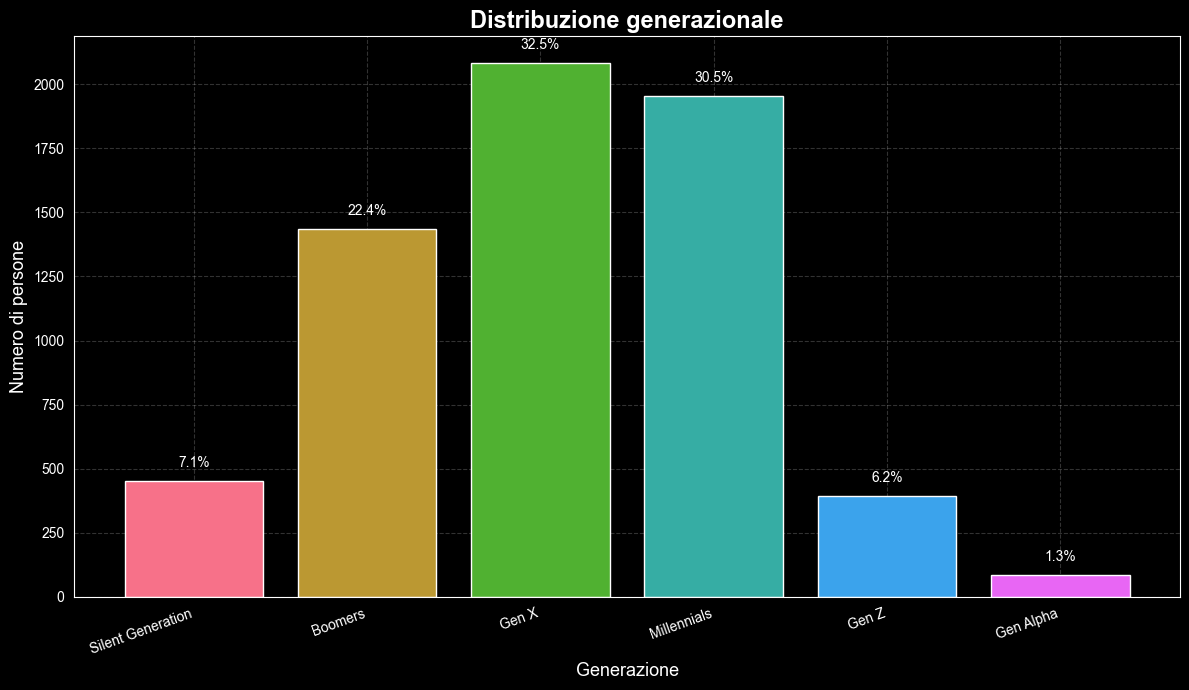

In [26]:
# preparazione dati
staff = (
    df_person_anime_works[["person_mal_id"]]
    .drop_duplicates()
    .merge(
        df_person_details[["person_mal_id", "birthday"]],
        on="person_mal_id",
        how="left"
    )
)
staff["birth_year"] = pd.to_datetime(
    staff["birthday"], errors="coerce",  utc=True
).dt.year
staff.loc[~staff["birth_year"].between(1900, 2024), "birth_year"] = pd.NA
labels = [
    "Silent Generation", "Boomers", "Gen X", "Millennials", "Gen Z", "Gen Alpha"]

staff["generation"] = pd.cut(
    staff["birth_year"],
    bins=[-np.inf, 1945, 1964, 1980, 1996, 2012, 2024],
    labels=labels
)
gen_counts = (
    staff["generation"]
    .value_counts()
    .reindex(labels, fill_value=0)
    .rename_axis("generation")
    .reset_index(name="count")
)
gen_counts["share"] = (
    gen_counts["count"] / gen_counts["count"].sum() * 100
).round(1)
# grafico
plt.figure(figsize=(12, 7))
colors = sns.color_palette("husl", n_colors=len(gen_counts))
bars = plt.bar(
    gen_counts["generation"],
    gen_counts["count"],
    color=colors
)
for bar, share in zip(bars, gen_counts["share"]):
    height = bar.get_height()
    plt.text(
    bar.get_x() + bar.get_width()/2.,
    height + gen_counts["count"].max() * 0.02,
    f'{share}%',
    ha='center',
    va='bottom',
    fontsize=10
)
plt.xlabel("Generazione", fontsize=13)
plt.ylabel("Numero di persone", fontsize=13)
plt.title("Distribuzione generazionale", fontsize=17, fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.grid(True, alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

Il grafico mostra la distribuzione generazionale delle persone presenti nei credits degli anime. Le generazioni più rappresentate sono **Gen X e Millennials**, seguite dai Boomers, mentre Gen Z e Gen Alpha risultano ancora meno presenti.

Questo riflette la struttura dell'industria: chi lavora oggi in posizioni centrali (registi, animatori, compositori) appartiene spesso a generazioni che hanno cresciuto professionalmente durante l'espansione globale degli anime negli anni '90 e 2000. Gen Z inizia a comparire, ma il peso del settore è ancora in mano alle generazioni precedenti.


> **Nota sui dati:** su 26.236 persone presenti nei credits anime, solo 6.409 avevano un anno di nascita valido tra 1900 e 2024. Il grafico rappresenta quindi il 24,4% del totale; le altre persone sono state escluse per assenza o non validità della data di nascita.

## Ruoli più frequenti e notorietà nell'industria anime

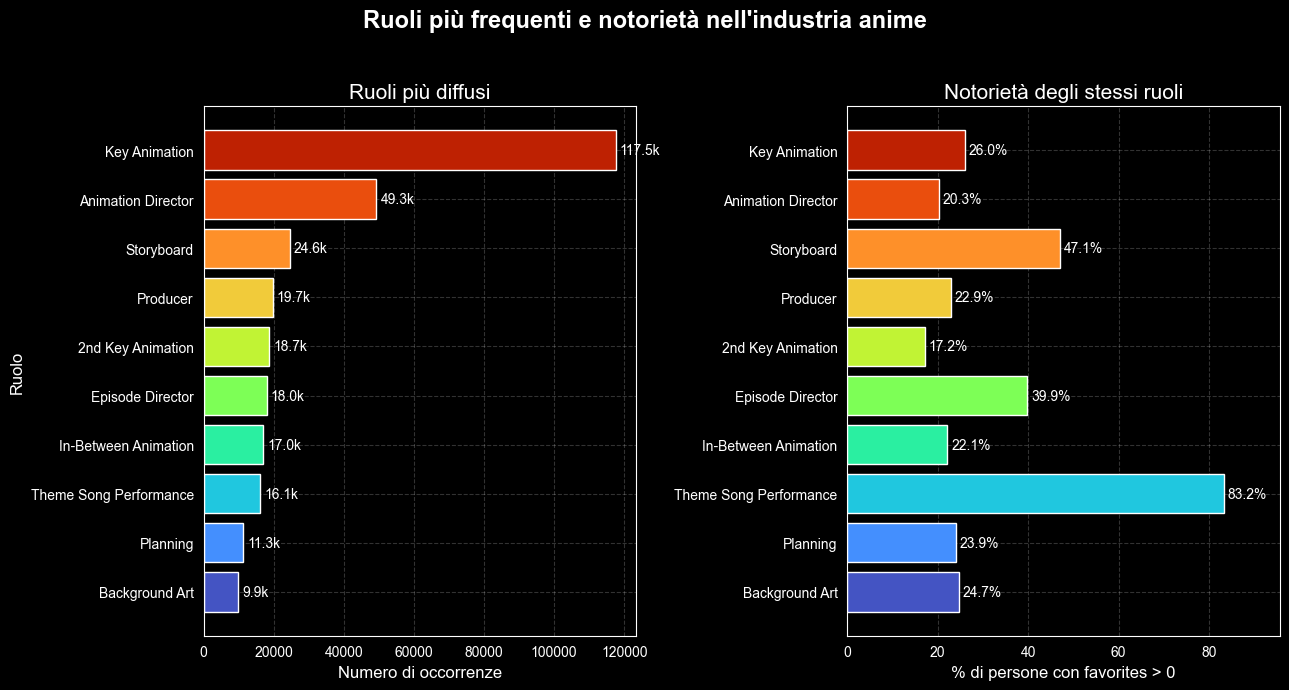

In [27]:
# Pulizia ruoli: rimuove le annotazioni episodio tipo "(ep 1-5)"
role_clean = df_person_anime_works["position"].str.split("(").str[0].str.strip()

top10 = (
    role_clean
    .value_counts()
    .head(10)
    .rename_axis("role")
    .reset_index(name="occurrences")
)
role_people = df_person_anime_works.copy()
role_people["role"] = role_clean
role_people = role_people.loc[
    role_people["role"].isin(top10["role"]), ["person_mal_id", "role"]
]
role_people = role_people.drop_duplicates(subset=["person_mal_id", "role"])
role_people = role_people.merge(
    df_person_details[["person_mal_id", "favorites"]], on="person_mal_id", how="left"
)
fav_stats = (
    role_people.groupby("role")["favorites"]
    .agg(share_nonzero=lambda x: (x.fillna(0) > 0).mean() * 100)
    .reset_index()
)
top10 = top10.merge(fav_stats, on="role", how="left").sort_values("occurrences", ascending=True)
colors = sns.color_palette("turbo", len(top10))
plt.figure(figsize=(13, 7))
# sinistra
plt.subplot(1, 2, 1)
bars1 = plt.barh(top10["role"], top10["occurrences"], color=colors)
for bar, val in zip(bars1, top10["occurrences"]):
    plt.text(
        bar.get_width() + top10["occurrences"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{val / 1000:.1f}k", va="center", fontsize=10
    )
plt.title("Ruoli più diffusi", fontsize=15)
plt.xlabel("Numero di occorrenze", fontsize=12)
plt.ylabel("Ruolo", fontsize=12)
plt.grid(True, alpha=0.2, linestyle="--")

# destra
plt.subplot(1, 2, 2)
bars2 = plt.barh(top10["role"], top10["share_nonzero"], color=colors)
for bar, val in zip(bars2, top10["share_nonzero"]):
    plt.text(
        bar.get_width() + top10["share_nonzero"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.1f}%", va="center", fontsize=10
    )
plt.title("Notorietà degli stessi ruoli", fontsize=15)
plt.xlabel("% di persone con favorites > 0", fontsize=12)
plt.xlim(0, top10["share_nonzero"].max() * 1.15)
plt.grid(True, alpha=0.2, linestyle="--")

plt.suptitle("Ruoli più frequenti e notorietà nell'industria anime", fontsize=17, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Il grafico confronta i ruoli più frequenti negli anime con la loro notorietà, misurata come percentuale di persone con almeno un favourite.

Il pattern è chiaro: **ruoli tecnici** come Key Animation **sono i più numerosi, ma tra i meno riconosciuti dal pubblico**. Al contrario, Original Creator e Director compaiono meno spesso nei credits, ma raccolgono la notorietà più alta.

Quantità e visibilità non coincidono mai del tutto nell'industria anime: chi fa il lavoro più voluminoso rimane spesso nell'ombra, mentre chi firma l'opera diventa il volto pubblico del progetto.


## Top 15 professionisti per nomi alternativi

Un professionista che lavora in molti paesi accumula nomi alternativi: traslitterazioni, pseudonimi, nomi d'arte in lingue diverse. Il numero di nomi alternativi è un indicatore della portata internazionale di una figura nell'industria anime.

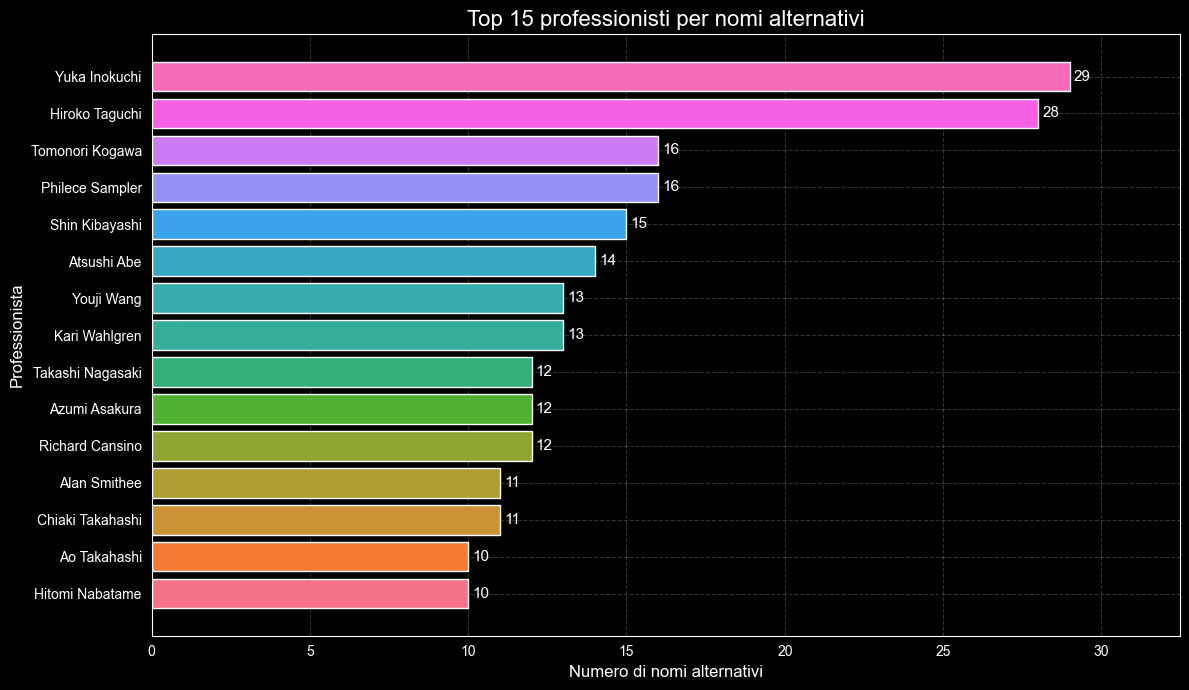

In [28]:
alt_names = df_person_alternate_names.copy()
person_details = df_person_details.copy()

alt_name_counts = (alt_names.groupby("person_mal_id").size().reset_index(name="alt_name_count"))

top_alt = (
    pd.merge(
        alt_name_counts.nlargest(15, "alt_name_count"),
        person_details[["person_mal_id", "name", "favorites"]],
        on="person_mal_id", how="left"
    )
    .sort_values("alt_name_count", ascending=True)
)

palette = sns.color_palette("husl", len(top_alt))
fig, ax = plt.subplots(figsize=(12, 7))


bars = ax.barh(top_alt["name"], top_alt["alt_name_count"], color=palette)
ax.set_title("Top 15 professionisti per nomi alternativi", fontsize=16)
ax.set_xlabel("Numero di nomi alternativi", fontsize=12)
ax.set_ylabel("Professionista", fontsize=12)
ax.bar_label(bars, padding=3, fontsize=11)
ax.set_xlim(0, top_alt["alt_name_count"].max() * 1.12)
plt.grid(True, alpha=0.2, linestyle='--')

plt.tight_layout()
plt.show()

I professionisti con più nomi alternativi sono spesso figure di rilievo internazionale, conosciute sotto forme diverse del loro nome in paesi e mercati differenti. Ogni nome alternativo rappresenta un mercato raggiunto, una community che ha adottato quel professionista nel proprio contesto culturale, riflettendo la circolazione globale dell'industria anime.

Dopo aver analizzato le persone che lavorano dietro agli anime, possiamo tornare al lato degli utenti e osservare come la community organizza la propria esperienza di visione: cosa guarda, cosa completa, cosa abbandona e cosa mette in lista per il futuro.

## 9. COME SONO SEGUITI GLI ANIME

Guardare anime non significa soltanto scegliere un titolo e valutarlo. Gli utenti costruiscono vere e proprie liste personali: anime completati, in corso, messi in pausa, abbandonati o pianificati per il futuro.

### Tra completati, abbandonati e pianificati: lo stato di visione

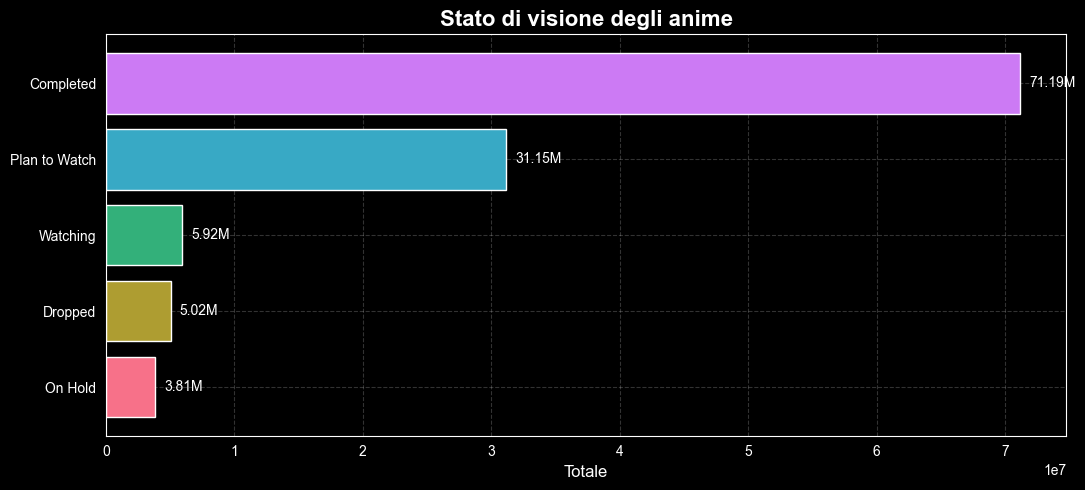

In [29]:
profiles = df_profiles.copy()

cols = utils.WATCH_STATUS_COLS
profiles[cols] = profiles[cols].fillna(0)

status_totals = profiles[cols].sum().rename_axis("status").reset_index(name="total")
status_totals["status"] = status_totals["status"].replace(utils.WATCH_STATUS_LABELS)
status_totals = status_totals.sort_values("total")

colors = sns.color_palette("husl", len(status_totals))

plt.figure(figsize=(11, 5))
bars = plt.barh(status_totals["status"], status_totals["total"], color=colors)
for bar, val in zip(bars, status_totals["total"]):
    plt.text(
        bar.get_width() + status_totals["total"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{val / 1_000_000:.2f}M", va="center", fontsize=10
    )
plt.title("Stato di visione degli anime", fontsize=16, fontweight="bold")
plt.xlabel("Totale", fontsize=12)
plt.grid(True, alpha=0.2, linestyle="--")
plt.tight_layout()
plt.show()

Il grafico mostra come gli utenti distribuiscono gli anime nelle proprie liste personali: completati, pianificati, in visione, abbandonati o messi in pausa.

La categoria **Completed** è nettamente la più alta, seguita da Plan to Watch, indicando che gli utenti usano la piattaforma sia per registrare ciò che hanno già visto sia per organizzare ciò che vogliono guardare in futuro.

Questo grafico non rappresenta solo la popolarità degli anime, ma anche il modo in cui gli utenti gestiscono il proprio rapporto con un catalogo enorme: alcuni titoli vengono completati, altri restano in lista, altri ancora vengono abbandonati o messi in pausa.

## Come cambia lo stato nel tempo?

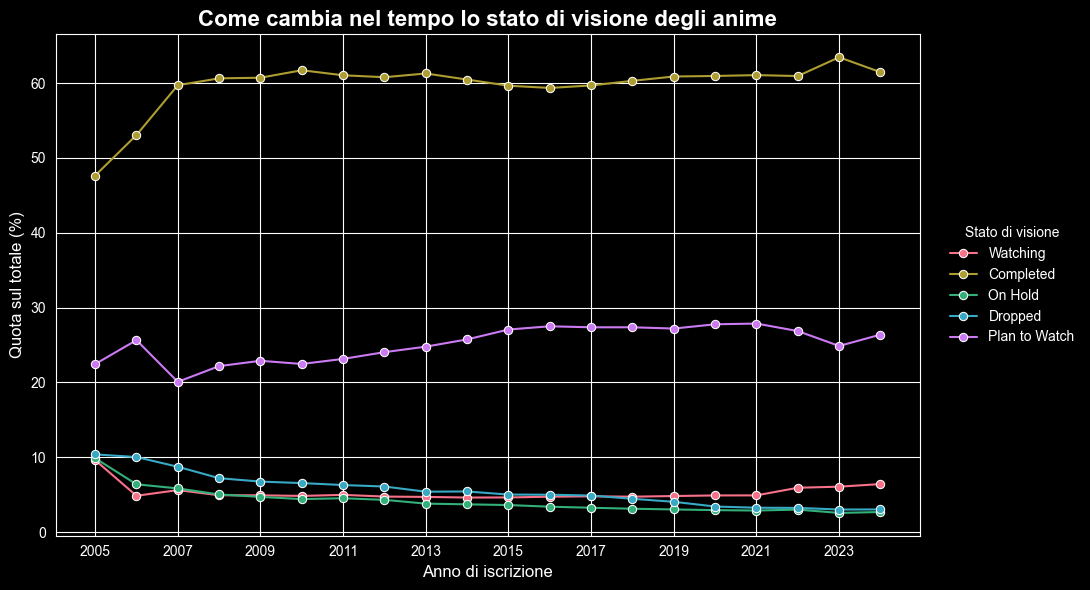

In [30]:
profiles = df_profiles.copy()

profiles["joined"] = pd.to_datetime(profiles["joined"], errors="coerce")
profiles["joined_year"] = profiles["joined"].dt.year

cols = utils.WATCH_STATUS_COLS
profiles[cols] = profiles[cols].fillna(0)

profiles = profiles.dropna(subset=["joined_year"])
profiles["joined_year"] = profiles["joined_year"].astype(int)
profiles = profiles[profiles["joined_year"].between(2005, 2024)]

status_palette = dict(zip(utils.WATCH_STATUS_ORDER, sns.color_palette("husl", len(utils.WATCH_STATUS_ORDER))))

cohort_totals = profiles.groupby("joined_year")[cols].sum().reset_index()
cohort_pct = cohort_totals.loc[cohort_totals[cols].sum(axis=1) > 0].copy()
cohort_pct[cols] = cohort_pct[cols].div(cohort_pct[cols].sum(axis=1), axis=0) * 100

cohort_long = cohort_pct.melt(
    id_vars="joined_year", value_vars=cols, var_name="status", value_name="share"
)
cohort_long["status"] = cohort_long["status"].replace(utils.WATCH_STATUS_LABELS)

plt.figure(figsize=(11, 6))
sns.lineplot(
    data=cohort_long, x="joined_year", y="share",
    hue="status", palette=status_palette, marker="o"
)
plt.title("Come cambia nel tempo lo stato di visione degli anime", fontsize=16, fontweight="bold")
plt.xlabel("Anno di iscrizione", fontsize=12)
plt.ylabel("Quota sul totale (%)", fontsize=12)
plt.xticks(cohort_pct["joined_year"][::2], cohort_pct["joined_year"][::2].astype(int))
plt.legend(title="Stato di visione", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.tight_layout()
plt.show()

Questo grafico mostra come cambia nel tempo la composizione degli stati di visione tra gli utenti registrati in anni diversi.

L’aspetto interessante non è solo quanti anime vengono guardati, ma come cambia il modo di gestirli: completare, pianificare o abbandonare un titolo diventano segnali del rapporto tra utenti e catalogo.
Notiamo che l’abbandono rimane relativamente basso rispetto ai titoli completati o pianificati.

In questo modo, la community non appare solo come un insieme di utenti, ma come un pubblico attivo che guarda, valuta, organizza e costruisce nel tempo il proprio rapporto con gli anime.


>**Nota sui dati:** Si considerano gli utenti con anno di iscrizione tra 2005-2024, per un totale di 20 anni. Sono stati esclusi 13.850 utenti fuori intervallo e 1.676 utenti con data non leggibile. Il grafico rappresenta quindi 321.628 utenti, pari al 95,4% del totale. I valori mancanti sono trattati come 0 e le percentuali sono calcolate sul totale degli stati di visione di ciascun anno.

## Completamento e abbandono: cosa rivelano le statistiche per anime

Oltre alle preferenze globali della community, il dataset fornisce statistiche dettagliate per ciascun anime: quanti utenti li hanno completati, quanti li hanno abbandonati. Questi dati raccontano il rapporto reale tra gli utenti e i singoli titoli, andando oltre la semplice popolarità.

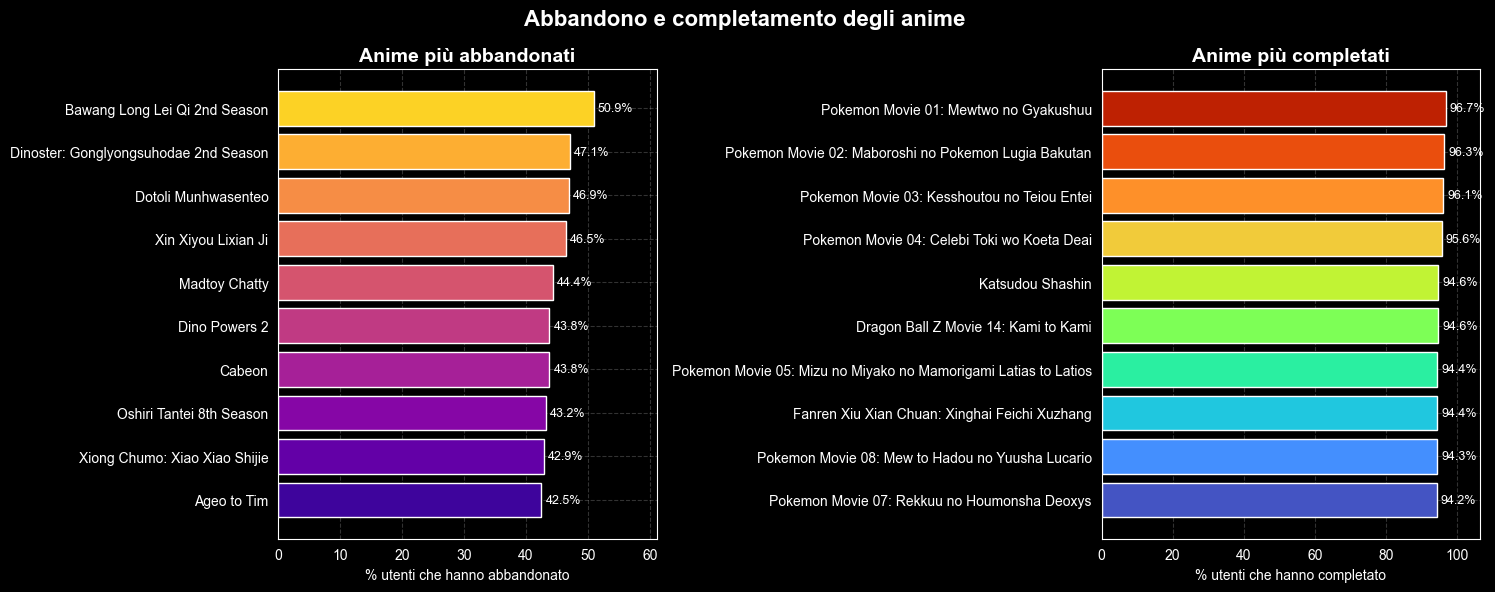

In [31]:
stats = df_stats.copy()
details = df_details.copy()

# considero solo anime con abbastanza utenti
stats = stats[stats["total"] >= 200].copy()
stats["completion_rate"] = stats["completed"] / stats["total"] * 100
stats["drop_rate"] = stats["dropped"] / stats["total"] * 100

merged_stats = stats.merge(details[["mal_id", "title"]], on="mal_id", how="inner")

most_dropped = (
    merged_stats.nlargest(10, "drop_rate")
    [["title", "drop_rate"]]
    .sort_values("drop_rate")
)

most_completed = (
    merged_stats[merged_stats["total"] >= 500]
    .nlargest(10, "completion_rate")
    [["title", "completion_rate"]]
    .sort_values("completion_rate")
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colors1 = sns.color_palette("plasma", len(most_dropped))
colors2 = sns.color_palette("turbo", len(most_completed))

bars1 = axes[0].barh(most_dropped["title"], most_dropped["drop_rate"], color=colors1)
axes[0].bar_label(bars1, fmt="%.1f%%", padding=3, fontsize=9)
axes[0].set_title("Anime più abbandonati", fontsize=14, fontweight="bold")
axes[0].set_xlabel("% utenti che hanno abbandonato")
axes[0].set_ylabel("")
axes[0].grid(True, alpha=0.2, linestyle='--')
axes[0].set_xlim(0, most_dropped["drop_rate"].max() * 1.2)

bars2 = axes[1].barh(most_completed["title"], most_completed["completion_rate"], color=colors2)
axes[1].bar_label(bars2, fmt="%.1f%%", padding=3, fontsize=9)
axes[1].set_title("Anime più completati", fontsize=14, fontweight="bold")
axes[1].set_xlabel("% utenti che hanno completato")
axes[1].set_ylabel("")
axes[1].grid(True, alpha=0.2, linestyle='--')
axes[1].set_xlim(0, most_completed["completion_rate"].max() * 1.1)


plt.suptitle("Abbandono e completamento degli anime", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

Il grafico confronta due comportamenti opposti: gli anime con il tasso di **abbandono** più alto e quelli con il tasso di **completamento** più elevato, considerando solo titoli con un numero minimo di utenti per evitare risultati poco rappresentativi.

Gli anime più completati superano quasi sempre il 90% di completamento: si tratta di titoli che riescono a mantenere l'attenzione degli utenti fino alla fine, indipendentemente dalla loro popolarità assoluta. Sul lato opposto, alcuni titoli vengono abbandonati da oltre la metà degli utenti che li iniziano.

Il completamento è quindi un indicatore più preciso della popolarità: non misura solo quante persone iniziano un anime, ma quante lo portano davvero fino all'ultimo episodio.


## 10. IL PUBBLICO A CUI SI RIVOLGONO GLI ANIME

Ogni anime non racconta solo una storia: si rivolge anche a un certo tipo di pubblico.

Dopo aver osservato produzione, popolarità, community e comportamento degli utenti, l’ultimo passaggio riguarda il target previsto: per chi vengono pensati gli anime e come questa struttura cambia nel tempo.

### Distribuzione dei target demografici

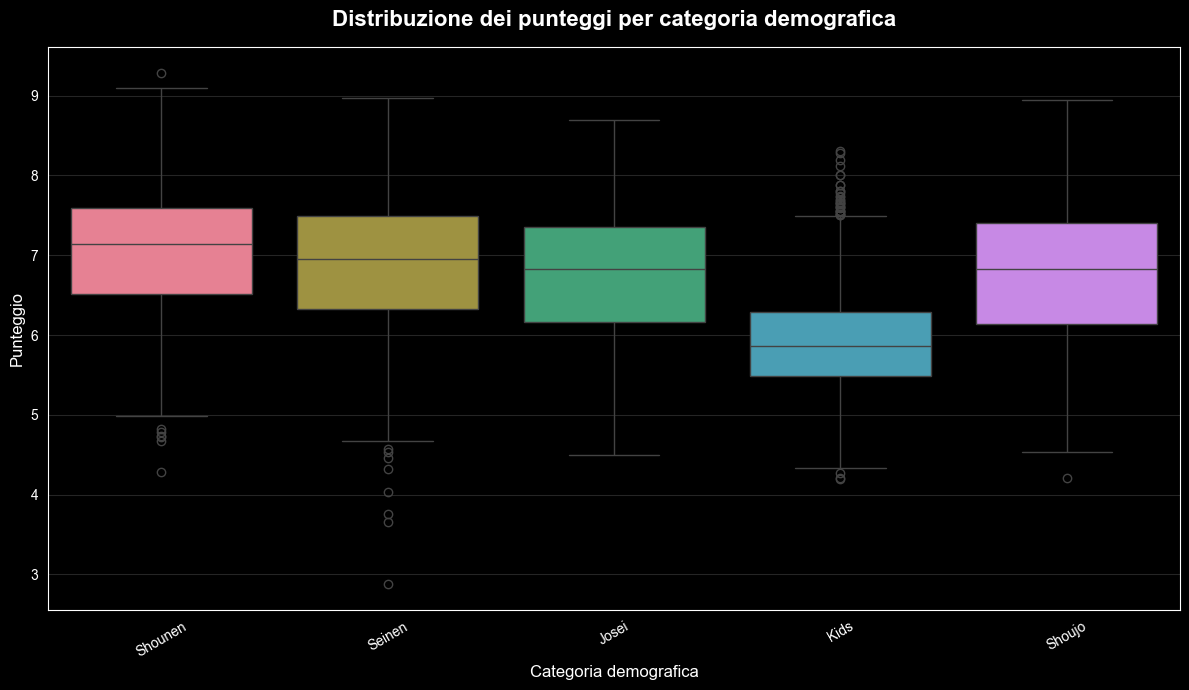

In [32]:
# preparazione dati
details = df_details.copy()
details["demographics"] = details["demographics"].apply(ast.literal_eval)
details = details.explode("demographics")
details["score"] = pd.to_numeric(details["score"], errors="coerce")
details_plot = details.dropna(subset=["demographics", "score"])
# grafico
plt.figure(figsize=(12, 7))
sns.boxplot(data=details_plot,x="demographics",y="score",hue="demographics",palette="husl",legend=False)
plt.title("Distribuzione dei punteggi per categoria demografica", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Categoria demografica", fontsize=12)
plt.ylabel("Punteggio", fontsize=12)
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.15)

plt.tight_layout()
plt.show()

Le categorie demografiche indicano il pubblico principale a cui l'anime è rivolto: **Shounen** = ragazzi adolescenti, **Shoujo** = ragazze adolescenti, **Seinen** = uomini giovani/adulti, **Josei** = donne giovani/adulte, **Kids** = bambini.

Il grafico mostra come variano i punteggi assegnati dagli utenti in base alla categoria demografica. **Shounen ha la mediana più alta**, attorno a 7.1: gli anime per ragazzi tendono a ricevere valutazioni alte e abbastanza uniformi.

**Kids si posiziona all'opposto**, con la mediana più bassa e una distribuzione più ampia verso i voti bassi. Questo non sorprende: gli anime per bambini vengono spesso valutati da adulti che non sono il pubblico originale, abbassando il punteggio complessivo.

**Seinen e Shoujo** si collocano su valori simili, intorno a 6.8–6.9. Seinen mostra una distribuzione leggermente più ampia, mentre Josei risulta più stabile, anche se ha meno titoli rappresentati.

Nel complesso, la categoria demografica non è solo un'etichetta di pubblico: influenza anche il modo in cui gli utenti percepiscono e valutano i titoli.

## Come evolgono nel tempo?

In [34]:
details = df_details.copy()
# filtro e preparazione
details = details[details['year'] < 2025].copy()
details['demographics'] = details['demographics'].apply(eval)
details = details.explode('demographics')
# conteggio per anno e demografico
counts = (details.groupby(['year', 'demographics']).size().reset_index(name='anime_count'))
# creazione grafico con Plotly
fig = px.line(counts, x='year', y='anime_count', color='demographics', markers=True,
    title="Evoluzione dei target demografici nel tempo",
    labels={'year': 'Anno', 'anime_count': 'Numero di titoli', 'demographics': 'Target Demografico'},
    hover_data={'year': True, 'anime_count': True, 'demographics': True})
fig.update_traces(marker=dict(size=5), line=dict(width=2))
fig.update_layout(
    xaxis=dict(range=[1917, 2024]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

Il grafico mostra come il numero di titoli per ciascuna categoria demografica sia cambiato nel corso di oltre un secolo. Le linee evidenziano un’evoluzione graduale fino agli anni ’70, seguita da un aumento più marcato in alcune categorie.
La crescita più evidente è quella della categoria Shounen, che a partire dagli anni ’70 accelera rapidamente fino a raggiungere un picco intorno al 2020. Questo andamento riflette l’enorme successo commerciale e culturale delle opere rivolte a un pubblico giovane maschile, spesso caratterizzate da azione, avventura e narrazioni seriali.
Le categorie Kids, Seinen, Shoujo e Josei mostrano invece una crescita più moderata, con incrementi costanti ma meno pronunciati. Questo suggerisce un’espansione complessiva dell’industria, ma con un’attenzione particolare verso i generi più popolari e redditizi.
Nel complesso, il grafico racconta una storia di diversificazione progressiva, ma anche di forte concentrazione su alcune fasce demografiche che hanno guidato l’evoluzione dell’animazione giapponese negli ultimi decenni.


---

## 11. CONCLUSIONE - GLI ANIME COME ECOSISTEMA CULTURALE E GLOBALE

Dalla crescita della produzione ai target demografici, il percorso mostra che gli anime funzionano come un ecosistema: opere, generi, utenti, personaggi, voci e professionisti si intrecciano nel tempo, costruendo un fenomeno culturale sempre più ampio.

**Produzione e qualità**

La produzione di anime è cresciuta enormemente nel tempo, raggiungendo il picco nel 2017. Quello che colpisce è che, nonostante l'aumento della quantità, la qualità percepita dagli utenti è rimasta stabile e alta. L'industria ha saputo espandersi senza abbassare gli standard.

**Generi e preferenze non sempre coincidono**

Comedy e Action dominano la produzione, ma le preferenze degli utenti risultano più distribuite. Alcuni generi vengono prodotti molto di più di quanto i fan li richiedano, mentre altri rimangono meno rappresentati pur essendo apprezzati. Questo mostra che l'industria segue logiche proprie, non sempre allineate al gusto del pubblico.

**Una community globale**

Gli utenti  sono presenti in tutto il mondo, ma chi crea gli anime è ancora prevalentemente giapponese. Il fenomeno anime è quindi un caso interessante di prodotto fortemente locale che ha raggiunto un pubblico globale, con una community cresciuta soprattutto dopo il 2000 e con un picco evidente durante il periodo pandemico.

**Gli utenti gestiscono attivamente la loro esperienza**

Le liste personali degli utenti  completati, pianificati, abbandonati  mostrano che guardare anime non è un'attività passiva. Il tasso di completamento emerge come un indicatore importante: non basta attirare attenzione, bisogna riuscire a mantenere l'interesse fino alla fine.

**Un mezzo, non un genere**

Il dato forse più significativo di tutto il percorso è la varietà demografica: Shounen, Shoujo, Seinen, Josei, Kids. Gli anime non si rivolgono a un pubblico unico, ma a fasce d'età e interessi molto diversi. Questa capacità di adattarsi a pubblici differenti è probabilmente uno dei motivi principali per cui il fenomeno continua a crescere.